In [1]:
import ast
import os

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

pd.set_option("display.max_columns", None)
pd.set_option("display.max_colwidth", 100)

In [2]:
DATA_PATH = "."

print("Files available:")
for file in os.listdir(DATA_PATH):
    print("-", file)

Files available:
- eda.ipynb
- ingr_map.pkl
- interactions_test.csv
- interactions_train.csv
- interactions_validation.csv
- PP_recipes.csv
- PP_users.csv
- RAW_interactions.csv
- RAW_recipes.csv


In [4]:
recipes = pd.read_csv(os.path.join(DATA_PATH, "RAW_recipes.csv"))

print("Shape:", recipes.shape)

Shape: (231637, 12)


In [5]:
recipes.head()

,name,id,minutes,contributor_id,submitted,tags,nutrition,n_steps,steps,description,ingredients,n_ingredients
0,arriba baked winter squash mexican style,137739,55,47892,2005-09-16,"['60-minutes-or-less', 'time-to-make', 'course', 'main-ingredient', 'cuisine', 'preparation', 'o...","[51.5, 0.0, 13.0, 0.0, 2.0, 0.0, 4.0]",11,"['make a choice and proceed with recipe', 'depending on size of squash , cut into half or fourth...",autumn is my favorite time of year to cook! this recipe \r\ncan be prepared either spicy or swee...,"['winter squash', 'mexican seasoning', 'mixed spice', 'honey', 'butter', 'olive oil', 'salt']",7
1,a bit different breakfast pizza,31490,30,26278,2002-06-17,"['30-minutes-or-less', 'time-to-make', 'course', 'main-ingredient', 'cuisine', 'preparation', 'o...","[173.4, 18.0, 0.0, 17.0, 22.0, 35.0, 1.0]",9,"['preheat oven to 425 degrees f', 'press dough into the bottom and sides of a 12 inch pizza pan'...",this recipe calls for the crust to be prebaked a bit before adding ingredients. feel free to cha...,"['prepared pizza crust', 'sausage patty', 'eggs', 'milk', 'salt and pepper', 'cheese']",6
2,all in the kitchen chili,112140,130,196586,2005-02-25,"['time-to-make', 'course', 'preparation', 'main-dish', 'chili', 'crock-pot-slow-cooker', 'dietar...","[269.8, 22.0, 32.0, 48.0, 39.0, 27.0, 5.0]",6,"['brown ground beef in large pot', 'add chopped onions to ground beef when almost brown and saut...",this modified version of 'mom's' chili was a hit at our 2004 christmas party. we made an extra l...,"['ground beef', 'yellow onions', 'diced tomatoes', 'tomato paste', 'tomato soup', 'rotel tomatoe...",13
3,alouette potatoes,59389,45,68585,2003-04-14,"['60-minutes-or-less', 'time-to-make', 'course', 'main-ingredient', 'preparation', 'occasion', '...","[368.1, 17.0, 10.0, 2.0, 14.0, 8.0, 20.0]",11,"['place potatoes in a large pot of lightly salted water and bring to a gentle boil', 'cook until...","this is a super easy, great tasting, make ahead side dish that looks like you spent a lot more t...","['spreadable cheese with garlic and herbs', 'new potatoes', 'shallots', 'parsley', 'tarragon', '...",11
4,amish tomato ketchup for canning,44061,190,41706,2002-10-25,"['weeknight', 'time-to-make', 'course', 'main-ingredient', 'cuisine', 'preparation', 'occasion',...","[352.9, 1.0, 337.0, 23.0, 3.0, 0.0, 28.0]",5,"['mix all ingredients& boil for 2 1 / 2 hours , or until thick', 'pour into jars', ""i use'old' g...",my dh's amish mother raised him on this recipe. he much prefers it over store-bought ketchup. it...,"['tomato juice', 'apple cider vinegar', 'sugar', 'salt', 'pepper', 'clove oil', 'cinnamon oil', ...",8


In [6]:
print("Number of rows:", recipes.shape[0])
print("Number of columns:", recipes.shape[1])

print("\nColumn names:")
print(recipes.columns.tolist())

Number of rows: 231637
Number of columns: 12

Column names:
['name', 'id', 'minutes', 'contributor_id', 'submitted', 'tags', 'nutrition', 'n_steps', 'steps', 'description', 'ingredients', 'n_ingredients']


In [7]:
recipes.info()

<class 'pandas.DataFrame'>
RangeIndex: 231637 entries, 0 to 231636
Data columns (total 12 columns):
 #   Column          Non-Null Count   Dtype
---  ------          --------------   -----
 0   name            231636 non-null  str  
 1   id              231637 non-null  int64
 2   minutes         231637 non-null  int64
 3   contributor_id  231637 non-null  int64
 4   submitted       231637 non-null  str  
 5   tags            231637 non-null  str  
 6   nutrition       231637 non-null  str  
 7   n_steps         231637 non-null  int64
 8   steps           231637 non-null  str  
 9   description     226658 non-null  str  
 10  ingredients     231637 non-null  str  
 11  n_ingredients   231637 non-null  int64
dtypes: int64(5), str(7)
memory usage: 21.2 MB


In [8]:
missing = pd.DataFrame(
    {"missing_count": recipes.isnull().sum(), "missing_percentage": recipes.isnull().mean() * 100}
)

missing = missing.sort_values("missing_percentage", ascending=False)

missing

,missing_count,missing_percentage
description,4979,2.149484
name,1,0.000432
minutes,0,0.000000
id,0,0.000000
contributor_id,0,0.000000
submitted,0,0.000000
nutrition,0,0.000000
tags,0,0.000000
n_steps,0,0.000000
steps,0,0.000000


In [9]:
print("Duplicate rows:", recipes.duplicated().sum())

Duplicate rows: 0


In [10]:
print("Duplicate recipe IDs:", recipes["id"].duplicated().sum())

Duplicate recipe IDs: 0


In [11]:
important_columns = [
    "id",
    "name",
    "minutes",
    "tags",
    "nutrition",
    "n_steps",
    "steps",
    "description",
    "ingredients",
    "n_ingredients",
]

existing_columns = [col for col in important_columns if col in recipes.columns]

recipes[existing_columns].head(5)

,id,name,minutes,tags,nutrition,n_steps,steps,description,ingredients,n_ingredients
0,137739,arriba baked winter squash mexican style,55,"['60-minutes-or-less', 'time-to-make', 'course', 'main-ingredient', 'cuisine', 'preparation', 'o...","[51.5, 0.0, 13.0, 0.0, 2.0, 0.0, 4.0]",11,"['make a choice and proceed with recipe', 'depending on size of squash , cut into half or fourth...",autumn is my favorite time of year to cook! this recipe \r\ncan be prepared either spicy or swee...,"['winter squash', 'mexican seasoning', 'mixed spice', 'honey', 'butter', 'olive oil', 'salt']",7
1,31490,a bit different breakfast pizza,30,"['30-minutes-or-less', 'time-to-make', 'course', 'main-ingredient', 'cuisine', 'preparation', 'o...","[173.4, 18.0, 0.0, 17.0, 22.0, 35.0, 1.0]",9,"['preheat oven to 425 degrees f', 'press dough into the bottom and sides of a 12 inch pizza pan'...",this recipe calls for the crust to be prebaked a bit before adding ingredients. feel free to cha...,"['prepared pizza crust', 'sausage patty', 'eggs', 'milk', 'salt and pepper', 'cheese']",6
2,112140,all in the kitchen chili,130,"['time-to-make', 'course', 'preparation', 'main-dish', 'chili', 'crock-pot-slow-cooker', 'dietar...","[269.8, 22.0, 32.0, 48.0, 39.0, 27.0, 5.0]",6,"['brown ground beef in large pot', 'add chopped onions to ground beef when almost brown and saut...",this modified version of 'mom's' chili was a hit at our 2004 christmas party. we made an extra l...,"['ground beef', 'yellow onions', 'diced tomatoes', 'tomato paste', 'tomato soup', 'rotel tomatoe...",13
3,59389,alouette potatoes,45,"['60-minutes-or-less', 'time-to-make', 'course', 'main-ingredient', 'preparation', 'occasion', '...","[368.1, 17.0, 10.0, 2.0, 14.0, 8.0, 20.0]",11,"['place potatoes in a large pot of lightly salted water and bring to a gentle boil', 'cook until...","this is a super easy, great tasting, make ahead side dish that looks like you spent a lot more t...","['spreadable cheese with garlic and herbs', 'new potatoes', 'shallots', 'parsley', 'tarragon', '...",11
4,44061,amish tomato ketchup for canning,190,"['weeknight', 'time-to-make', 'course', 'main-ingredient', 'cuisine', 'preparation', 'occasion',...","[352.9, 1.0, 337.0, 23.0, 3.0, 0.0, 28.0]",5,"['mix all ingredients& boil for 2 1 / 2 hours , or until thick', 'pour into jars', ""i use'old' g...",my dh's amish mother raised him on this recipe. he much prefers it over store-bought ketchup. it...,"['tomato juice', 'apple cider vinegar', 'sugar', 'salt', 'pepper', 'clove oil', 'cinnamon oil', ...",8


In [12]:
recipes.describe(include="all").T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
name,231636,230185,banana chocolate chip muffins,3,NaN,NaN,NaN,NaN,NaN,NaN,NaN
id,231637.0,NaN,NaN,NaN,222014.708984,141206.635626,38.0,99944.0,207249.0,333816.0,537716.0
minutes,231637.0,NaN,NaN,NaN,9398.546009,4461963.03886,0.0,20.0,40.0,65.0,2147483647.0
contributor_id,231637.0,NaN,NaN,NaN,5534885.113838,99791408.213902,27.0,56905.0,173614.0,398275.0,2002289981.0
submitted,231637,5090,2000-03-06,470,NaN,NaN,NaN,NaN,NaN,NaN,NaN
tags,231637,209115,"['15-minutes-or-less', 'time-to-make', 'course', 'preparation', 'for-1-or-2', '5-ingredients-or-...",397,NaN,NaN,NaN,NaN,NaN,NaN,NaN
nutrition,231637,229318,"[69.4, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0]",36,NaN,NaN,NaN,NaN,NaN,NaN,NaN
n_steps,231637.0,NaN,NaN,NaN,9.765499,5.995128,0.0,6.0,9.0,12.0,145.0
steps,231637,231074,['blend all ingredients until smooth'],20,NaN,NaN,NaN,NaN,NaN,NaN,NaN
description,226658,222668,yum,153,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [13]:
recipes.describe().T

,count,mean,std,min,25%,50%,75%,max
id,231637.0,2.220147e+05,1.412066e+05,38.0,99944.0,207249.0,333816.0,5.377160e+05
minutes,231637.0,9.398546e+03,4.461963e+06,0.0,20.0,40.0,65.0,2.147484e+09
contributor_id,231637.0,5.534885e+06,9.979141e+07,27.0,56905.0,173614.0,398275.0,2.002290e+09
n_steps,231637.0,9.765499e+00,5.995128e+00,0.0,6.0,9.0,12.0,1.450000e+02
n_ingredients,231637.0,9.051153e+00,3.734796e+00,1.0,6.0,9.0,11.0,4.300000e+01


In [14]:
recipes["minutes"].describe()

count    2.316370e+05
mean     9.398546e+03
std      4.461963e+06
min      0.000000e+00
25%      2.000000e+01
50%      4.000000e+01
75%      6.500000e+01
max      2.147484e+09
Name: minutes, dtype: float64

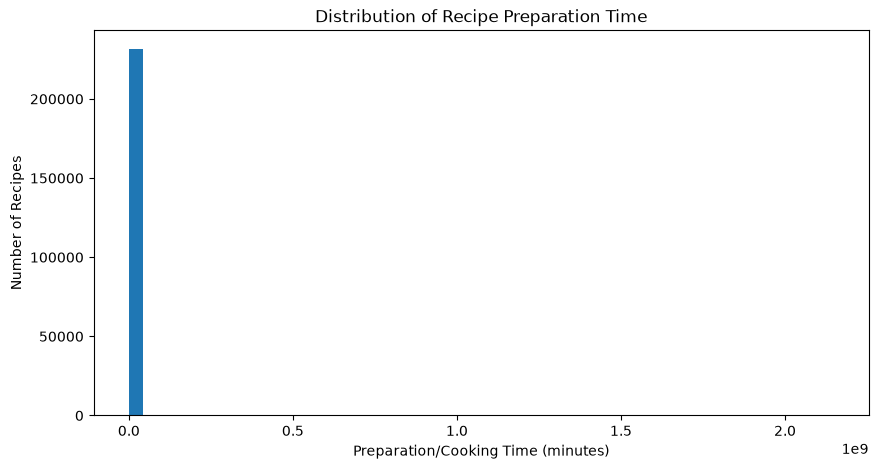

In [15]:
plt.figure(figsize=(10, 5))

plt.hist(recipes["minutes"].dropna(), bins=50)

plt.xlabel("Preparation/Cooking Time (minutes)")
plt.ylabel("Number of Recipes")
plt.title("Distribution of Recipe Preparation Time")

plt.show()

In [16]:
recipes["n_ingredients"].describe()

count    231637.000000
mean          9.051153
std           3.734796
min           1.000000
25%           6.000000
50%           9.000000
75%          11.000000
max          43.000000
Name: n_ingredients, dtype: float64

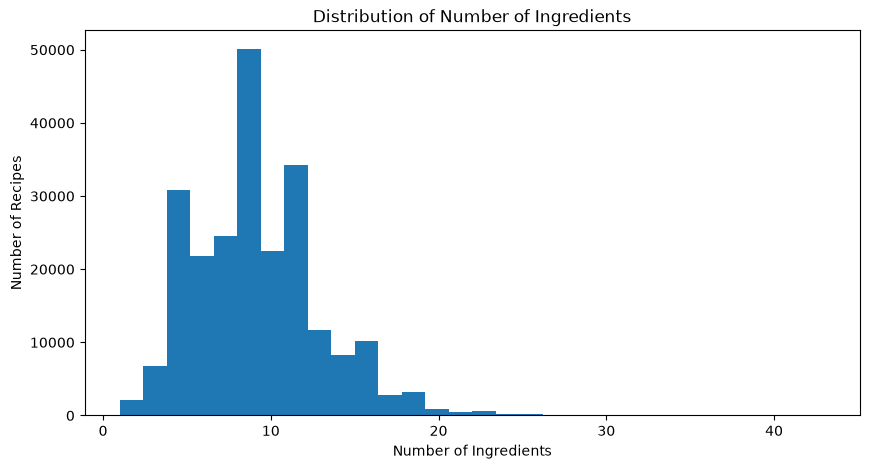

In [17]:
plt.figure(figsize=(10, 5))

plt.hist(recipes["n_ingredients"].dropna(), bins=30)

plt.xlabel("Number of Ingredients")
plt.ylabel("Number of Recipes")
plt.title("Distribution of Number of Ingredients")

plt.show()

In [18]:
for i, ingredients in enumerate(recipes["ingredients"].head(20)):
    print(f"\nRecipe {i + 1}:")
    print(ingredients)


Recipe 1:
['winter squash', 'mexican seasoning', 'mixed spice', 'honey', 'butter', 'olive oil', 'salt']

Recipe 2:
['prepared pizza crust', 'sausage patty', 'eggs', 'milk', 'salt and pepper', 'cheese']

Recipe 3:
['ground beef', 'yellow onions', 'diced tomatoes', 'tomato paste', 'tomato soup', 'rotel tomatoes', 'kidney beans', 'water', 'chili powder', 'ground cumin', 'salt', 'lettuce', 'cheddar cheese']

Recipe 4:
['spreadable cheese with garlic and herbs', 'new potatoes', 'shallots', 'parsley', 'tarragon', 'olive oil', 'red wine vinegar', 'salt', 'pepper', 'red bell pepper', 'yellow bell pepper']

Recipe 5:
['tomato juice', 'apple cider vinegar', 'sugar', 'salt', 'pepper', 'clove oil', 'cinnamon oil', 'dry mustard']

Recipe 6:
['milk', 'vanilla ice cream', 'frozen apple juice concentrate', 'apple']

Recipe 7:
['fennel seeds', 'green olives', 'ripe olives', 'garlic', 'peppercorn', 'orange rind', 'orange juice', 'red chile', 'extra virgin olive oil']

Recipe 8:
['pork spareribs', 'soy 

In [19]:
print(type(recipes["ingredients"].iloc[0]))

<class 'str'>


In [20]:
def parse_list(value):
    try:
        return ast.literal_eval(value)
    except (ValueError, SyntaxError, TypeError):
        return []


recipes["ingredients_list"] = recipes["ingredients"].apply(parse_list)

In [21]:
recipes[["name", "ingredients", "ingredients_list"]].head()

,name,ingredients,ingredients_list
0,arriba baked winter squash mexican style,"['winter squash', 'mexican seasoning', 'mixed spice', 'honey', 'butter', 'olive oil', 'salt']","[winter squash, mexican seasoning, mixed spice, honey, butter, olive oil, salt]"
1,a bit different breakfast pizza,"['prepared pizza crust', 'sausage patty', 'eggs', 'milk', 'salt and pepper', 'cheese']","[prepared pizza crust, sausage patty, eggs, milk, salt and pepper, cheese]"
2,all in the kitchen chili,"['ground beef', 'yellow onions', 'diced tomatoes', 'tomato paste', 'tomato soup', 'rotel tomatoe...","[ground beef, yellow onions, diced tomatoes, tomato paste, tomato soup, rotel tomatoes, kidney b..."
3,alouette potatoes,"['spreadable cheese with garlic and herbs', 'new potatoes', 'shallots', 'parsley', 'tarragon', '...","[spreadable cheese with garlic and herbs, new potatoes, shallots, parsley, tarragon, olive oil, ..."
4,amish tomato ketchup for canning,"['tomato juice', 'apple cider vinegar', 'sugar', 'salt', 'pepper', 'clove oil', 'cinnamon oil', ...","[tomato juice, apple cider vinegar, sugar, salt, pepper, clove oil, cinnamon oil, dry mustard]"


In [22]:
print(type(recipes["ingredients_list"].iloc[0]))

<class 'list'>


In [23]:
from collections import Counter

ingredient_counter = Counter()

for ingredient_list in recipes["ingredients_list"]:
    for ingredient in ingredient_list:
        ingredient_counter[ingredient.strip().lower()] += 1

top_ingredients = pd.DataFrame(
    ingredient_counter.most_common(30), columns=["ingredient", "recipe_count"]
)

top_ingredients

,ingredient,recipe_count
0,salt,85746
1,butter,54975
2,sugar,44535
3,onion,39065
4,water,34914
5,eggs,33761
6,olive oil,32822
7,flour,26266
8,milk,25786
9,garlic cloves,25748


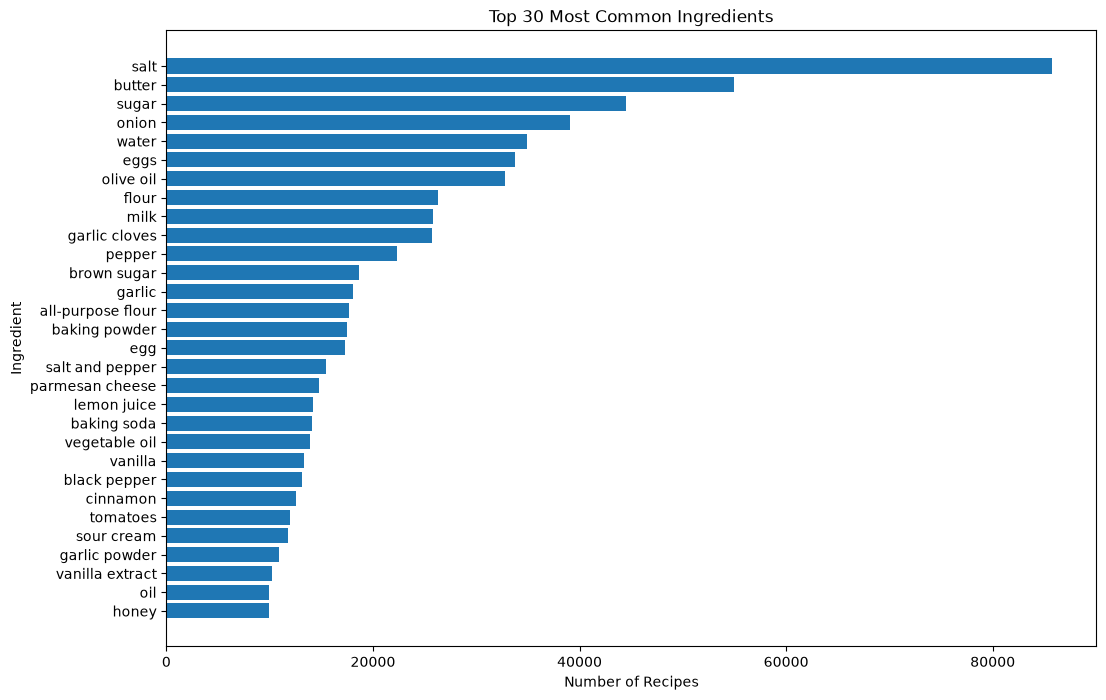

In [24]:
plt.figure(figsize=(12, 8))

plt.barh(top_ingredients["ingredient"][::-1], top_ingredients["recipe_count"][::-1])

plt.xlabel("Number of Recipes")
plt.ylabel("Ingredient")
plt.title("Top 30 Most Common Ingredients")

plt.show()

In [25]:
for tags in recipes["tags"].head(20):
    print(tags)

['60-minutes-or-less', 'time-to-make', 'course', 'main-ingredient', 'cuisine', 'preparation', 'occasion', 'north-american', 'side-dishes', 'vegetables', 'mexican', 'easy', 'fall', 'holiday-event', 'vegetarian', 'winter', 'dietary', 'christmas', 'seasonal', 'squash']
['30-minutes-or-less', 'time-to-make', 'course', 'main-ingredient', 'cuisine', 'preparation', 'occasion', 'north-american', 'breakfast', 'main-dish', 'pork', 'american', 'oven', 'easy', 'kid-friendly', 'pizza', 'dietary', 'northeastern-united-states', 'meat', 'equipment']
['time-to-make', 'course', 'preparation', 'main-dish', 'chili', 'crock-pot-slow-cooker', 'dietary', 'equipment', '4-hours-or-less']
['60-minutes-or-less', 'time-to-make', 'course', 'main-ingredient', 'preparation', 'occasion', 'side-dishes', 'eggs-dairy', 'potatoes', 'vegetables', 'oven', 'easy', 'dinner-party', 'holiday-event', 'easter', 'cheese', 'stove-top', 'dietary', 'christmas', 'new-years', 'thanksgiving', 'independence-day', 'st-patricks-day', 'val

In [26]:
recipes["tags_list"] = recipes["tags"].apply(parse_list)

recipes[["name", "tags_list"]].head(10)

,name,tags_list
0,arriba baked winter squash mexican style,"[60-minutes-or-less, time-to-make, course, main-ingredient, cuisine, preparation, occasion, nort..."
1,a bit different breakfast pizza,"[30-minutes-or-less, time-to-make, course, main-ingredient, cuisine, preparation, occasion, nort..."
2,all in the kitchen chili,"[time-to-make, course, preparation, main-dish, chili, crock-pot-slow-cooker, dietary, equipment,..."
3,alouette potatoes,"[60-minutes-or-less, time-to-make, course, main-ingredient, preparation, occasion, side-dishes, ..."
4,amish tomato ketchup for canning,"[weeknight, time-to-make, course, main-ingredient, cuisine, preparation, occasion, north-america..."
5,apple a day milk shake,"[15-minutes-or-less, time-to-make, course, main-ingredient, cuisine, preparation, occasion, nort..."
6,aww marinated olives,"[15-minutes-or-less, time-to-make, course, main-ingredient, cuisine, preparation, occasion, nort..."
7,backyard style barbecued ribs,"[weeknight, time-to-make, course, main-ingredient, cuisine, preparation, occasion, north-america..."
8,bananas 4 ice cream pie,"[weeknight, time-to-make, course, main-ingredient, preparation, pies-and-tarts, desserts, lunch,..."
9,beat this banana bread,"[weeknight, time-to-make, course, main-ingredient, preparation, occasion, breads, breakfast, fru..."


In [27]:
tag_counter = Counter()

for tag_list in recipes["tags_list"]:
    for tag in tag_list:
        tag_counter[tag.strip().lower()] += 1

top_tags = pd.DataFrame(tag_counter.most_common(50), columns=["tag", "recipe_count"])

top_tags

,tag,recipe_count
0,preparation,230546
1,time-to-make,225326
2,course,218148
3,main-ingredient,170446
4,dietary,165091
5,easy,126062
6,occasion,114145
7,cuisine,91165
8,low-in-something,85776
9,main-dish,71786


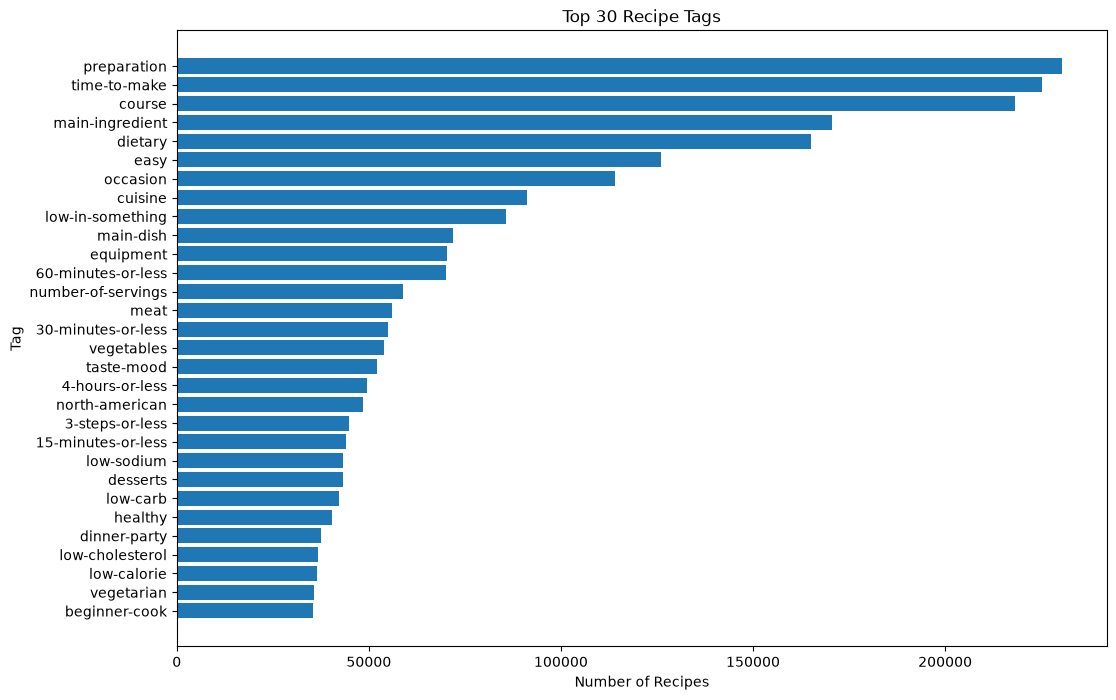

In [28]:
plt.figure(figsize=(12, 8))

plt.barh(top_tags["tag"].head(30)[::-1], top_tags["recipe_count"].head(30)[::-1])

plt.xlabel("Number of Recipes")
plt.ylabel("Tag")
plt.title("Top 30 Recipe Tags")

plt.show()

In [29]:
recipes["description"].head(20)

0     autumn is my favorite time of year to cook! this recipe \r\ncan be prepared either spicy or swee...
1     this recipe calls for the crust to be prebaked a bit before adding ingredients. feel free to cha...
2     this modified version of 'mom's' chili was a hit at our 2004 christmas party. we made an extra l...
3     this is a super easy, great tasting, make ahead side dish that looks like you spent a lot more t...
4     my dh's amish mother raised him on this recipe. he much prefers it over store-bought ketchup. it...
5                                                                                                     NaN
6     my italian mil was thoroughly impressed by my non-italian treatment of her olives. they are grea...
7                       this recipe is posted by request and was originaly from chef sam choy's cookbook 
8                                                                                                     NaN
9                                             

In [30]:
recipes["description_length"] = recipes["description"].fillna("").str.len()

recipes["description_length"].describe()

count    231637.000000
mean        195.582264
std         176.340046
min           0.000000
25%          79.000000
50%         151.000000
75%         258.000000
max        6321.000000
Name: description_length, dtype: float64

In [31]:
recipes[["name", "n_steps", "steps"]].head(10)

,name,n_steps,steps
0,arriba baked winter squash mexican style,11,"['make a choice and proceed with recipe', 'depending on size of squash , cut into half or fourth..."
1,a bit different breakfast pizza,9,"['preheat oven to 425 degrees f', 'press dough into the bottom and sides of a 12 inch pizza pan'..."
2,all in the kitchen chili,6,"['brown ground beef in large pot', 'add chopped onions to ground beef when almost brown and saut..."
3,alouette potatoes,11,"['place potatoes in a large pot of lightly salted water and bring to a gentle boil', 'cook until..."
4,amish tomato ketchup for canning,5,"['mix all ingredients& boil for 2 1 / 2 hours , or until thick', 'pour into jars', ""i use'old' g..."
5,apple a day milk shake,4,"['combine ingredients in blender', 'cover and blend until smooth', 'sprinkle with ground cinnamo..."
6,aww marinated olives,4,"['toast the fennel seeds and lightly crush them', 'place all the ingredients in a bowl , stir we..."
7,backyard style barbecued ribs,10,"['in a medium saucepan combine all the ingredients for sauce#1 , bring to a full rolling boil , ..."
8,bananas 4 ice cream pie,8,"['crumble cookies into a 9-inch pie plate , or cake pan', 'pat down to form an even layer', 'dri..."
9,beat this banana bread,12,"['preheat oven to 350 degrees', 'butter two 9x5"" loaf pans', 'cream the sugar and the butter unt..."


In [32]:
recipes["n_steps"].describe()

count    231637.000000
mean          9.765499
std           5.995128
min           0.000000
25%           6.000000
50%           9.000000
75%          12.000000
max         145.000000
Name: n_steps, dtype: float64

In [33]:
for nutrition in recipes["nutrition"].head(20):
    print(nutrition)

[51.5, 0.0, 13.0, 0.0, 2.0, 0.0, 4.0]
[173.4, 18.0, 0.0, 17.0, 22.0, 35.0, 1.0]
[269.8, 22.0, 32.0, 48.0, 39.0, 27.0, 5.0]
[368.1, 17.0, 10.0, 2.0, 14.0, 8.0, 20.0]
[352.9, 1.0, 337.0, 23.0, 3.0, 0.0, 28.0]
[160.2, 10.0, 55.0, 3.0, 9.0, 20.0, 7.0]
[380.7, 53.0, 7.0, 24.0, 6.0, 24.0, 6.0]
[1109.5, 83.0, 378.0, 275.0, 96.0, 86.0, 36.0]
[4270.8, 254.0, 1306.0, 111.0, 127.0, 431.0, 220.0]
[2669.3, 160.0, 976.0, 107.0, 62.0, 310.0, 138.0]
[79.2, 3.0, 58.0, 0.0, 0.0, 6.0, 5.0]
[734.1, 66.0, 199.0, 10.0, 10.0, 117.0, 28.0]
[462.4, 28.0, 214.0, 69.0, 14.0, 29.0, 23.0]
[315.8, 0.0, 202.0, 9.0, 6.0, 0.0, 21.0]
[8.2, 0.0, 0.0, 0.0, 1.0, 0.0, 0.0]
[105.7, 8.0, 0.0, 26.0, 5.0, 4.0, 3.0]
[94.0, 10.0, 0.0, 11.0, 11.0, 21.0, 0.0]
[232.7, 21.0, 77.0, 4.0, 6.0, 38.0, 8.0]
[395.4, 31.0, 20.0, 29.0, 51.0, 33.0, 8.0]
[174.2, 4.0, 24.0, 1.0, 15.0, 1.0, 10.0]


In [34]:
print(type(recipes["nutrition"].iloc[0]))

<class 'str'>


In [37]:
from collections import Counter

# Count every individual tag
tag_counter = Counter()

for tag_list in recipes["tags_list"]:
    for tag in tag_list:
        tag_counter[tag.strip().lower()] += 1

# Convert to DataFrame
all_tags = (
    pd.DataFrame(tag_counter.items(), columns=["tag", "recipe_count"])
    .sort_values("recipe_count", ascending=False)
    .reset_index(drop=True)
)

print("Total unique tags:", len(all_tags))

all_tags.head(50)

Total unique tags: 552


,tag,recipe_count
0,preparation,230546
1,time-to-make,225326
2,course,218148
3,main-ingredient,170446
4,dietary,165091
5,easy,126062
6,occasion,114145
7,cuisine,91165
8,low-in-something,85776
9,main-dish,71786


In [38]:
cuisine_keywords = [
    "indian",
    "south indian",
    "north indian",
    "chinese",
    "asian",
    "western",
    "italian",
    "mexican",
    "thai",
    "japanese",
    "korean",
    "french",
    "greek",
    "mediterranean",
    "american",
    "british",
    "spanish",
    "middle eastern",
    "indonesian",
    "vietnamese",
]

cuisine_tags = all_tags[
    all_tags["tag"].apply(lambda x: any(keyword in x for keyword in cuisine_keywords))
]

cuisine_tags

,tag,recipe_count
18,north-american,48479
37,american,31179
65,asian,13485
97,italian,7410
104,mexican,6694
146,southwestern-united-states,3536
155,midwestern,2884
159,indian,2708
167,greek,2391
176,french,2268


In [39]:
cuisine_tagged_recipes = recipes[
    recipes["tags_list"].apply(lambda tags: "cuisine" in [str(t).lower() for t in tags])
]

print("Recipes with explicit 'cuisine' tag:", len(cuisine_tagged_recipes))

cuisine_tagged_recipes[["name", "tags_list"]].head(20)

Recipes with explicit 'cuisine' tag: 91165


,name,tags_list
0,arriba baked winter squash mexican style,"[60-minutes-or-less, time-to-make, course, main-ingredient, cuisine, preparation, occasion, nort..."
1,a bit different breakfast pizza,"[30-minutes-or-less, time-to-make, course, main-ingredient, cuisine, preparation, occasion, nort..."
4,amish tomato ketchup for canning,"[weeknight, time-to-make, course, main-ingredient, cuisine, preparation, occasion, north-america..."
5,apple a day milk shake,"[15-minutes-or-less, time-to-make, course, main-ingredient, cuisine, preparation, occasion, nort..."
6,aww marinated olives,"[15-minutes-or-less, time-to-make, course, main-ingredient, cuisine, preparation, occasion, nort..."
7,backyard style barbecued ribs,"[weeknight, time-to-make, course, main-ingredient, cuisine, preparation, occasion, north-america..."
12,better then bush s baked beans,"[weeknight, time-to-make, course, main-ingredient, cuisine, preparation, occasion, north-america..."
16,chile rellenos,"[60-minutes-or-less, time-to-make, course, main-ingredient, cuisine, preparation, north-american..."
18,chinese chop suey,"[weeknight, time-to-make, course, main-ingredient, cuisine, preparation, occasion, north-america..."
19,cream of cauliflower soup vegan,"[lactose, weeknight, time-to-make, course, main-ingredient, cuisine, preparation, occasion, nort..."


In [40]:
[tag for tag in all_tags["tag"] if "cuisine" in tag]

['cuisine']

In [41]:
indian_tags = all_tags[all_tags["tag"].str.contains("indian", case=False, na=False)]

indian_tags

,tag,recipe_count
159,indian,2708


In [42]:
indian_recipes = recipes[
    recipes["tags_list"].apply(lambda tags: any("indian" in str(tag).lower() for tag in tags))
]

print("Indian-related recipes:", len(indian_recipes))

indian_recipes[["name", "tags_list"]].head(20)

Indian-related recipes: 2708


,name,tags_list
25,emotional balance spice mixture,"[15-minutes-or-less, time-to-make, course, cuisine, preparation, condiments-etc, asian, indian, ..."
65,munch without guilt tomatoes,"[15-minutes-or-less, time-to-make, course, main-ingredient, cuisine, preparation, occasion, low-..."
77,pour over anything mushroom gravy,"[30-minutes-or-less, time-to-make, course, main-ingredient, cuisine, preparation, occasion, sauc..."
100,tide me over indian chaat simple veggie salad,"[15-minutes-or-less, time-to-make, course, main-ingredient, cuisine, preparation, occasion, for-..."
179,creamy chicken curry,"[curries, lactose, time-to-make, course, main-ingredient, cuisine, preparation, occasion, main-d..."
181,denauseating with ginger tea,"[15-minutes-or-less, time-to-make, course, cuisine, preparation, occasion, 5-ingredients-or-less..."
271,seva bean vegetable stew,"[60-minutes-or-less, time-to-make, course, main-ingredient, cuisine, preparation, occasion, heal..."
597,chicken tikka masala vegan style,"[weeknight, time-to-make, course, main-ingredient, cuisine, preparation, occasion, main-dish, ve..."
632,leftover turkey biryani with red onion and cilantro,"[curries, 60-minutes-or-less, time-to-make, course, main-ingredient, cuisine, preparation, occas..."
672,paki garam masala,"[15-minutes-or-less, time-to-make, course, cuisine, preparation, condiments-etc, asian, indian, ..."


In [43]:
south_indian = recipes[
    recipes["tags_list"].apply(lambda tags: any("south indian" in str(tag).lower() for tag in tags))
]

north_indian = recipes[
    recipes["tags_list"].apply(lambda tags: any("north indian" in str(tag).lower() for tag in tags))
]

print("South Indian recipes:", len(south_indian))
print("North Indian recipes:", len(north_indian))

South Indian recipes: 0
North Indian recipes: 0


In [44]:
print("South Indian examples:")
display(south_indian[["name", "tags_list"]].head(10))

print("\nNorth Indian examples:")
display(north_indian[["name", "tags_list"]].head(10))

South Indian examples:


,name,tags_list



North Indian examples:


,name,tags_list


In [45]:
dietary_keywords = [
    "diabetic",
    "diabetes",
    "low-sodium",
    "low sodium",
    "low-carb",
    "low carb",
    "low-cholesterol",
    "low cholesterol",
    "low-saturated-fat",
    "low saturated fat",
    "healthy",
    "vegetarian",
    "vegan",
    "high-protein",
    "high protein",
    "fat-free",
    "low-fat",
    "low fat",
    "sugar-free",
    "sugar free",
]

dietary_tags = all_tags[
    all_tags["tag"].apply(lambda x: any(keyword in x for keyword in dietary_keywords))
]

dietary_tags

,tag,recipe_count
21,low-sodium,43349
23,low-carb,42189
24,healthy,40340
26,low-cholesterol,36743
28,vegetarian,35651
34,low-saturated-fat,31378
42,healthy-2,26619
49,low-fat,22170
81,vegan,10012
85,very-low-carbs,9201


In [46]:
dietary_tags.sort_values("recipe_count", ascending=False).reset_index(drop=True)

,tag,recipe_count
0,low-sodium,43349
1,low-carb,42189
2,healthy,40340
3,low-cholesterol,36743
4,vegetarian,35651
5,low-saturated-fat,31378
6,healthy-2,26619
7,low-fat,22170
8,vegan,10012
9,very-low-carbs,9201


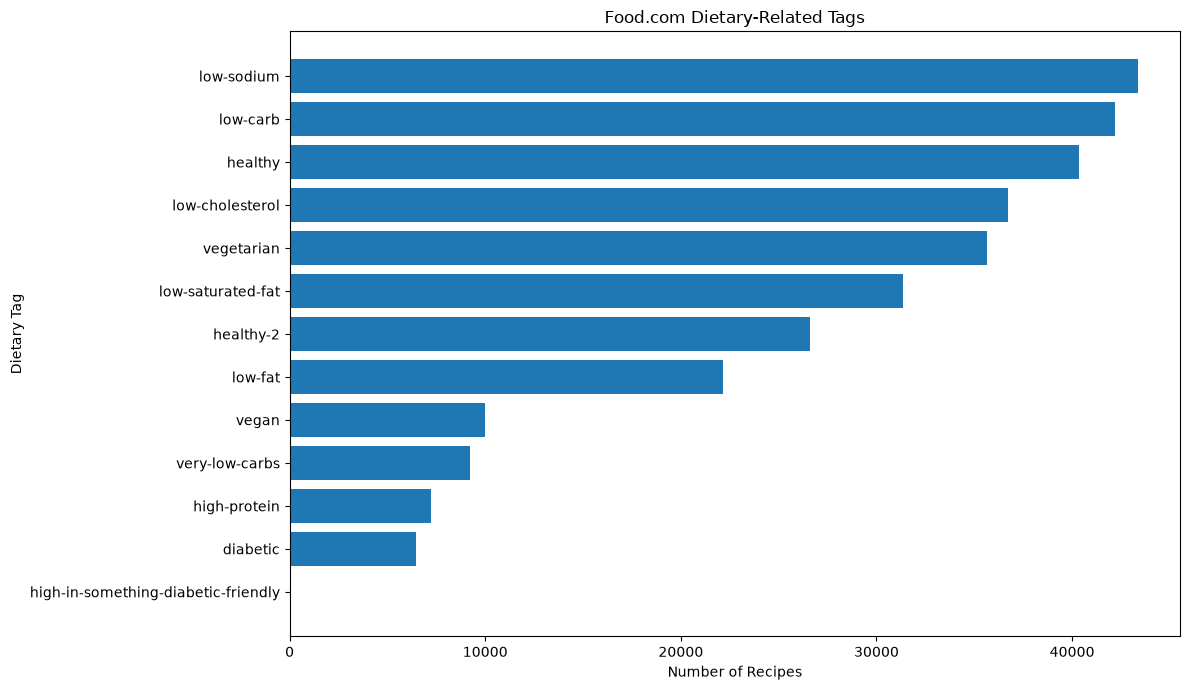

In [47]:
top_dietary = dietary_tags.head(20)

plt.figure(figsize=(12, 7))

plt.barh(top_dietary["tag"][::-1], top_dietary["recipe_count"][::-1])

plt.xlabel("Number of Recipes")
plt.ylabel("Dietary Tag")
plt.title("Food.com Dietary-Related Tags")

plt.tight_layout()
plt.show()

In [48]:
meal_keywords = [
    "breakfast",
    "lunch",
    "dinner",
    "snack",
    "dessert",
    "appetizer",
    "main-dish",
    "main dish",
    "side-dish",
    "side dish",
    "beverage",
]

meal_tags = all_tags[
    all_tags["tag"].apply(lambda x: any(keyword in x for keyword in meal_keywords))
]

meal_tags

,tag,recipe_count
9,main-dish,71786
22,desserts,43203
25,dinner-party,37561
41,side-dishes,26902
47,lunch,23800
54,appetizers,20379
64,breakfast,13655
75,beverages,11124
99,snacks,7159
187,frozen-desserts,1955


In [49]:
time_tags = all_tags[
    all_tags["tag"].str.contains("minutes|hour|quick|fast|easy", case=False, na=False)
]

time_tags.head(50)

,tag,recipe_count
5,easy,126062
11,60-minutes-or-less,69990
14,30-minutes-or-less,55077
17,4-hours-or-less,49497
20,15-minutes-or-less,43934
64,breakfast,13655
116,quick-breads,5652
503,breakfast-eggs,2
513,breakfast-potatoes,1
523,breakfast-casseroles,1


In [50]:
vegetarian_recipes = recipes[
    recipes["tags_list"].apply(lambda tags: any(str(tag).lower() == "vegetarian" for tag in tags))
]

vegan_recipes = recipes[
    recipes["tags_list"].apply(lambda tags: any(str(tag).lower() == "vegan" for tag in tags))
]

print("Vegetarian recipes:", len(vegetarian_recipes))
print("Vegan recipes:", len(vegan_recipes))

Vegetarian recipes: 35651
Vegan recipes: 10012


In [51]:
def has_tag(tags, keyword):
    keyword = keyword.lower()
    return any(keyword == str(tag).lower() for tag in tags)


recipe_metadata = pd.DataFrame(
    {
        "recipe_id": recipes["id"],
        "name": recipes["name"],
        "minutes": recipes["minutes"],
        "n_steps": recipes["n_steps"],
        "n_ingredients": recipes["n_ingredients"],
        "description": recipes["description"],
        "is_vegetarian": recipes["tags_list"].apply(lambda x: has_tag(x, "vegetarian")),
        "is_vegan": recipes["tags_list"].apply(lambda x: has_tag(x, "vegan")),
        "is_low_sodium": recipes["tags_list"].apply(lambda x: has_tag(x, "low-sodium")),
        "is_low_carb": recipes["tags_list"].apply(lambda x: has_tag(x, "low-carb")),
        "is_low_cholesterol": recipes["tags_list"].apply(lambda x: has_tag(x, "low-cholesterol")),
        "is_low_fat": recipes["tags_list"].apply(lambda x: has_tag(x, "low-fat")),
    }
)

recipe_metadata.head()

,recipe_id,name,minutes,n_steps,n_ingredients,description,is_vegetarian,is_vegan,is_low_sodium,is_low_carb,is_low_cholesterol,is_low_fat
0,137739,arriba baked winter squash mexican style,55,11,7,autumn is my favorite time of year to cook! this recipe \r\ncan be prepared either spicy or swee...,True,False,False,False,False,False
1,31490,a bit different breakfast pizza,30,9,6,this recipe calls for the crust to be prebaked a bit before adding ingredients. feel free to cha...,False,False,False,False,False,False
2,112140,all in the kitchen chili,130,6,13,this modified version of 'mom's' chili was a hit at our 2004 christmas party. we made an extra l...,False,False,False,False,False,False
3,59389,alouette potatoes,45,11,11,"this is a super easy, great tasting, make ahead side dish that looks like you spent a lot more t...",False,False,False,False,False,False
4,44061,amish tomato ketchup for canning,190,5,8,my dh's amish mother raised him on this recipe. he much prefers it over store-bought ketchup. it...,True,False,False,False,False,False


In [52]:
metadata_summary = pd.DataFrame(
    {
        "feature": ["Vegetarian", "Vegan", "Low Sodium", "Low Carb", "Low Cholesterol", "Low Fat"],
        "recipe_count": [
            recipe_metadata["is_vegetarian"].sum(),
            recipe_metadata["is_vegan"].sum(),
            recipe_metadata["is_low_sodium"].sum(),
            recipe_metadata["is_low_carb"].sum(),
            recipe_metadata["is_low_cholesterol"].sum(),
            recipe_metadata["is_low_fat"].sum(),
        ],
    }
)

metadata_summary

,feature,recipe_count
0,Vegetarian,35651
1,Vegan,10012
2,Low Sodium,43349
3,Low Carb,42189
4,Low Cholesterol,36743
5,Low Fat,22170


In [53]:
metadata_summary["percentage"] = metadata_summary["recipe_count"] / len(recipes) * 100

metadata_summary

,feature,recipe_count,percentage
0,Vegetarian,35651,15.390892
1,Vegan,10012,4.322280
2,Low Sodium,43349,18.714195
3,Low Carb,42189,18.213412
4,Low Cholesterol,36743,15.862319
5,Low Fat,22170,9.571010


In [54]:
cuisine_categories = {
    "Indian": ["indian"],
    "Chinese": ["chinese"],
    "Italian": ["italian"],
    "Mexican": ["mexican"],
    "Thai": ["thai"],
    "Japanese": ["japanese"],
    "Korean": ["korean"],
    "French": ["french"],
    "Greek": ["greek"],
    "Mediterranean": ["mediterranean"],
    "American": ["american"],
    "British": ["british"],
    "Spanish": ["spanish"],
    "Middle Eastern": ["middle eastern"],
    "Vietnamese": ["vietnamese"],
}

cuisine_summary = []

for cuisine, keywords in cuisine_categories.items():
    count = (
        recipes["tags_list"]
        .apply(
            lambda tags, keywords=keywords: any(
                keyword in str(tag).lower() for tag in tags for keyword in keywords
            )
        )
        .sum()
    )

    cuisine_summary.append({"cuisine": cuisine, "recipe_count": count})

cuisine_summary = pd.DataFrame(cuisine_summary)

cuisine_summary.sort_values("recipe_count", ascending=False)

,cuisine,recipe_count
10,American,49532
2,Italian,7410
3,Mexican,6694
0,Indian,2708
8,Greek,2391
7,French,2268
1,Chinese,2015
4,Thai,1208
12,Spanish,1072
5,Japanese,851


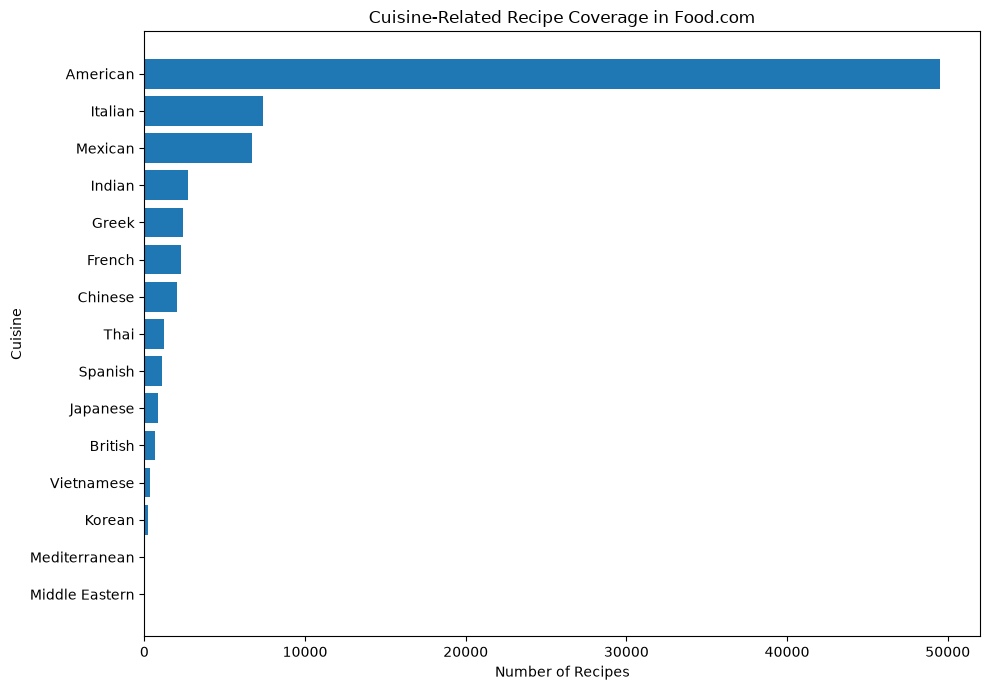

In [55]:
plot_data = cuisine_summary.sort_values("recipe_count", ascending=True)

plt.figure(figsize=(10, 7))

plt.barh(plot_data["cuisine"], plot_data["recipe_count"])

plt.xlabel("Number of Recipes")
plt.ylabel("Cuisine")
plt.title("Cuisine-Related Recipe Coverage in Food.com")

plt.tight_layout()
plt.show()

In [56]:
def get_cuisines(tags):
    found = []

    for cuisine, keywords in cuisine_categories.items():
        if any(keyword in str(tag).lower() for tag in tags for keyword in keywords):
            found.append(cuisine)

    return found


recipes["cuisine_candidates"] = recipes["tags_list"].apply(get_cuisines)

recipes[recipes["cuisine_candidates"].apply(len) > 0][["name", "cuisine_candidates"]].head(20)

,name,cuisine_candidates
0,arriba baked winter squash mexican style,"[Mexican, American]"
1,a bit different breakfast pizza,[American]
4,amish tomato ketchup for canning,[American]
5,apple a day milk shake,[American]
6,aww marinated olives,[American]
7,backyard style barbecued ribs,[American]
12,better then bush s baked beans,[American]
16,chile rellenos,[American]
18,chinese chop suey,[American]
19,cream of cauliflower soup vegan,[American]


In [57]:
recipes_with_cuisine = recipes["cuisine_candidates"].apply(len).gt(0)

print("Recipes with identified cuisine:", recipes_with_cuisine.sum())

print("Percentage:", recipes_with_cuisine.mean() * 100)

Recipes with identified cuisine: 68631
Percentage: 29.628686263420782


In [58]:
all_tags.to_csv("foodcom_all_tags_eda.csv", index=False)

dietary_tags.to_csv("foodcom_dietary_tags_eda.csv", index=False)

cuisine_summary.to_csv("foodcom_cuisine_summary_eda.csv", index=False)

metadata_summary.to_csv("foodcom_metadata_summary_eda.csv", index=False)

In [59]:
len(all_tags)

552

In [60]:
cuisine_summary.sort_values("recipe_count", ascending=False)

,cuisine,recipe_count
10,American,49532
2,Italian,7410
3,Mexican,6694
0,Indian,2708
8,Greek,2391
7,French,2268
1,Chinese,2015
4,Thai,1208
12,Spanish,1072
5,Japanese,851


In [61]:
metadata_summary

,feature,recipe_count,percentage
0,Vegetarian,35651,15.390892
1,Vegan,10012,4.322280
2,Low Sodium,43349,18.714195
3,Low Carb,42189,18.213412
4,Low Cholesterol,36743,15.862319
5,Low Fat,22170,9.571010


In [62]:
all_tags.head(30)

,tag,recipe_count
0,preparation,230546
1,time-to-make,225326
2,course,218148
3,main-ingredient,170446
4,dietary,165091
5,easy,126062
6,occasion,114145
7,cuisine,91165
8,low-in-something,85776
9,main-dish,71786


In [63]:
print(recipes_with_cuisine.sum())
print(recipes_with_cuisine.mean() * 100)

68631
29.628686263420782


In [64]:
# Display some raw nutrition values

for i, value in enumerate(recipes["nutrition"].head(20)):
    print(f"Recipe {i + 1}: {value}")

Recipe 1: [51.5, 0.0, 13.0, 0.0, 2.0, 0.0, 4.0]
Recipe 2: [173.4, 18.0, 0.0, 17.0, 22.0, 35.0, 1.0]
Recipe 3: [269.8, 22.0, 32.0, 48.0, 39.0, 27.0, 5.0]
Recipe 4: [368.1, 17.0, 10.0, 2.0, 14.0, 8.0, 20.0]
Recipe 5: [352.9, 1.0, 337.0, 23.0, 3.0, 0.0, 28.0]
Recipe 6: [160.2, 10.0, 55.0, 3.0, 9.0, 20.0, 7.0]
Recipe 7: [380.7, 53.0, 7.0, 24.0, 6.0, 24.0, 6.0]
Recipe 8: [1109.5, 83.0, 378.0, 275.0, 96.0, 86.0, 36.0]
Recipe 9: [4270.8, 254.0, 1306.0, 111.0, 127.0, 431.0, 220.0]
Recipe 10: [2669.3, 160.0, 976.0, 107.0, 62.0, 310.0, 138.0]
Recipe 11: [79.2, 3.0, 58.0, 0.0, 0.0, 6.0, 5.0]
Recipe 12: [734.1, 66.0, 199.0, 10.0, 10.0, 117.0, 28.0]
Recipe 13: [462.4, 28.0, 214.0, 69.0, 14.0, 29.0, 23.0]
Recipe 14: [315.8, 0.0, 202.0, 9.0, 6.0, 0.0, 21.0]
Recipe 15: [8.2, 0.0, 0.0, 0.0, 1.0, 0.0, 0.0]
Recipe 16: [105.7, 8.0, 0.0, 26.0, 5.0, 4.0, 3.0]
Recipe 17: [94.0, 10.0, 0.0, 11.0, 11.0, 21.0, 0.0]
Recipe 18: [232.7, 21.0, 77.0, 4.0, 6.0, 38.0, 8.0]
Recipe 19: [395.4, 31.0, 20.0, 29.0, 51.0, 33.

In [65]:
print("Data type of nutrition column:")
print(recipes["nutrition"].dtype)

print("\nData type of first nutrition value:")
print(type(recipes["nutrition"].iloc[0]))

Data type of nutrition column:
str

Data type of first nutrition value:
<class 'str'>


In [66]:
def parse_nutrition(value):
    try:
        return ast.literal_eval(value)
    except (ValueError, SyntaxError, TypeError):
        return []


recipes["nutrition_list"] = recipes["nutrition"].apply(parse_nutrition)

In [67]:
recipes[["name", "nutrition", "nutrition_list"]].head(10)

,name,nutrition,nutrition_list
0,arriba baked winter squash mexican style,"[51.5, 0.0, 13.0, 0.0, 2.0, 0.0, 4.0]","[51.5, 0.0, 13.0, 0.0, 2.0, 0.0, 4.0]"
1,a bit different breakfast pizza,"[173.4, 18.0, 0.0, 17.0, 22.0, 35.0, 1.0]","[173.4, 18.0, 0.0, 17.0, 22.0, 35.0, 1.0]"
2,all in the kitchen chili,"[269.8, 22.0, 32.0, 48.0, 39.0, 27.0, 5.0]","[269.8, 22.0, 32.0, 48.0, 39.0, 27.0, 5.0]"
3,alouette potatoes,"[368.1, 17.0, 10.0, 2.0, 14.0, 8.0, 20.0]","[368.1, 17.0, 10.0, 2.0, 14.0, 8.0, 20.0]"
4,amish tomato ketchup for canning,"[352.9, 1.0, 337.0, 23.0, 3.0, 0.0, 28.0]","[352.9, 1.0, 337.0, 23.0, 3.0, 0.0, 28.0]"
5,apple a day milk shake,"[160.2, 10.0, 55.0, 3.0, 9.0, 20.0, 7.0]","[160.2, 10.0, 55.0, 3.0, 9.0, 20.0, 7.0]"
6,aww marinated olives,"[380.7, 53.0, 7.0, 24.0, 6.0, 24.0, 6.0]","[380.7, 53.0, 7.0, 24.0, 6.0, 24.0, 6.0]"
7,backyard style barbecued ribs,"[1109.5, 83.0, 378.0, 275.0, 96.0, 86.0, 36.0]","[1109.5, 83.0, 378.0, 275.0, 96.0, 86.0, 36.0]"
8,bananas 4 ice cream pie,"[4270.8, 254.0, 1306.0, 111.0, 127.0, 431.0, 220.0]","[4270.8, 254.0, 1306.0, 111.0, 127.0, 431.0, 220.0]"
9,beat this banana bread,"[2669.3, 160.0, 976.0, 107.0, 62.0, 310.0, 138.0]","[2669.3, 160.0, 976.0, 107.0, 62.0, 310.0, 138.0]"


In [68]:
print(type(recipes["nutrition_list"].iloc[0]))
print(recipes["nutrition_list"].iloc[0])

<class 'list'>
[51.5, 0.0, 13.0, 0.0, 2.0, 0.0, 4.0]


In [69]:
nutrition_lengths = recipes["nutrition_list"].apply(len)

print(nutrition_lengths.value_counts().sort_index())

nutrition_list
7    231637
Name: count, dtype: int64


In [70]:
print("Recipes with 7 nutrition values:", (nutrition_lengths == 7).sum())

print("Recipes with 0 nutrition values:", (nutrition_lengths == 0).sum())

print("Recipes with other lengths:", (~nutrition_lengths.isin([0, 7])).sum())

Recipes with 7 nutrition values: 231637
Recipes with 0 nutrition values: 0
Recipes with other lengths: 0


In [71]:
nutrition_columns = [
    "calories",
    "total_fat",
    "sugar",
    "sodium",
    "protein",
    "saturated_fat",
    "carbohydrates",
]

for i, column in enumerate(nutrition_columns):
    recipes[column] = recipes["nutrition_list"].apply(
        lambda x, i=i: x[i] if len(x) == 7 else np.nan
    )

In [72]:
recipes[["name", *nutrition_columns]].head(10)

,name,calories,total_fat,sugar,sodium,protein,saturated_fat,carbohydrates
0,arriba baked winter squash mexican style,51.5,0.0,13.0,0.0,2.0,0.0,4.0
1,a bit different breakfast pizza,173.4,18.0,0.0,17.0,22.0,35.0,1.0
2,all in the kitchen chili,269.8,22.0,32.0,48.0,39.0,27.0,5.0
3,alouette potatoes,368.1,17.0,10.0,2.0,14.0,8.0,20.0
4,amish tomato ketchup for canning,352.9,1.0,337.0,23.0,3.0,0.0,28.0
5,apple a day milk shake,160.2,10.0,55.0,3.0,9.0,20.0,7.0
6,aww marinated olives,380.7,53.0,7.0,24.0,6.0,24.0,6.0
7,backyard style barbecued ribs,1109.5,83.0,378.0,275.0,96.0,86.0,36.0
8,bananas 4 ice cream pie,4270.8,254.0,1306.0,111.0,127.0,431.0,220.0
9,beat this banana bread,2669.3,160.0,976.0,107.0,62.0,310.0,138.0


In [73]:
nutrition_summary = recipes[nutrition_columns].describe().T

nutrition_summary

,count,mean,std,min,25%,50%,75%,max
calories,231637.0,473.942425,1189.711374,0.0,174.4,313.4,519.7,434360.2
total_fat,231637.0,36.080700,77.798840,0.0,8.0,20.0,41.0,17183.0
sugar,231637.0,84.296865,800.080897,0.0,9.0,25.0,68.0,362729.0
sodium,231637.0,30.147485,131.961589,0.0,5.0,14.0,33.0,29338.0
protein,231637.0,34.681860,58.472480,0.0,7.0,18.0,51.0,6552.0
saturated_fat,231637.0,45.589150,98.235758,0.0,7.0,23.0,52.0,10395.0
carbohydrates,231637.0,15.560403,81.824560,0.0,4.0,9.0,16.0,36098.0


In [74]:
nutrition_missing = pd.DataFrame(
    {
        "missing_count": recipes[nutrition_columns].isnull().sum(),
        "missing_percentage": recipes[nutrition_columns].isnull().mean() * 100,
    }
)

nutrition_missing

,missing_count,missing_percentage
calories,0,0.0
total_fat,0,0.0
sugar,0,0.0
sodium,0,0.0
protein,0,0.0
saturated_fat,0,0.0
carbohydrates,0,0.0


In [75]:
zero_summary = pd.DataFrame(
    {
        "zero_count": (recipes[nutrition_columns] == 0).sum(),
        "zero_percentage": (recipes[nutrition_columns] == 0).mean() * 100,
    }
)

zero_summary

,zero_count,zero_percentage
calories,53,0.022881
total_fat,16770,7.239776
sugar,10322,4.456110
sodium,19841,8.565557
protein,9837,4.246731
saturated_fat,19732,8.518501
carbohydrates,13068,5.641586


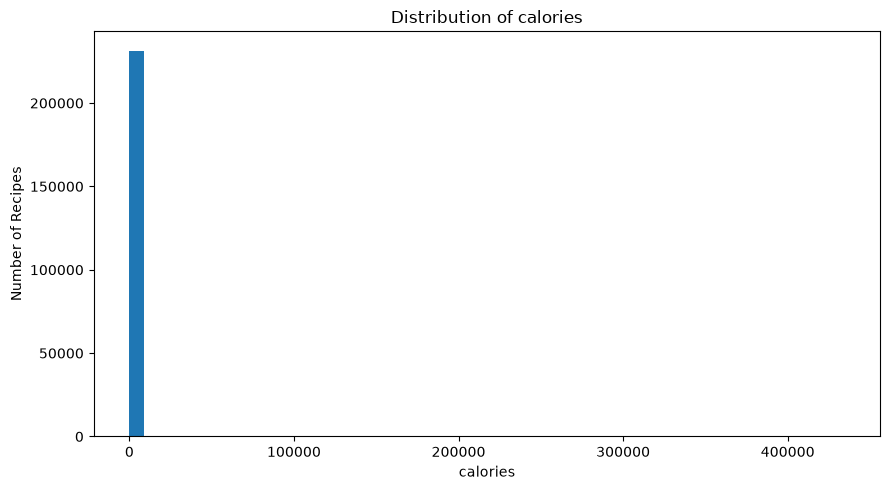

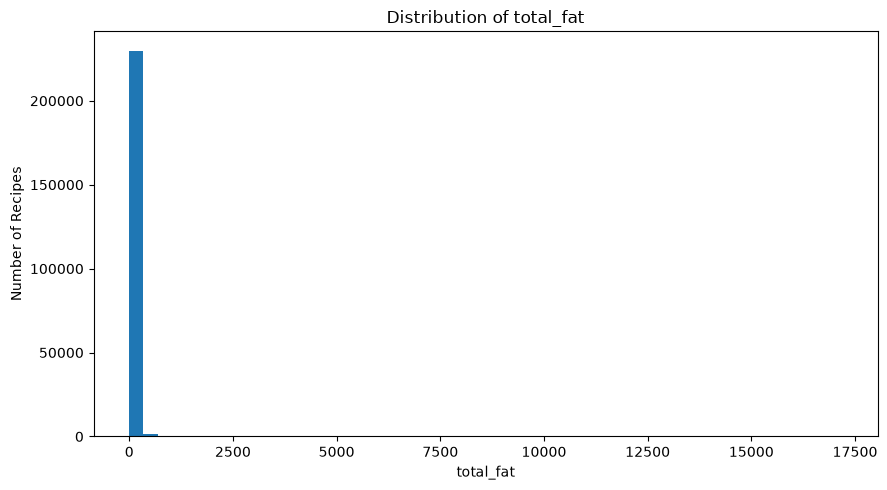

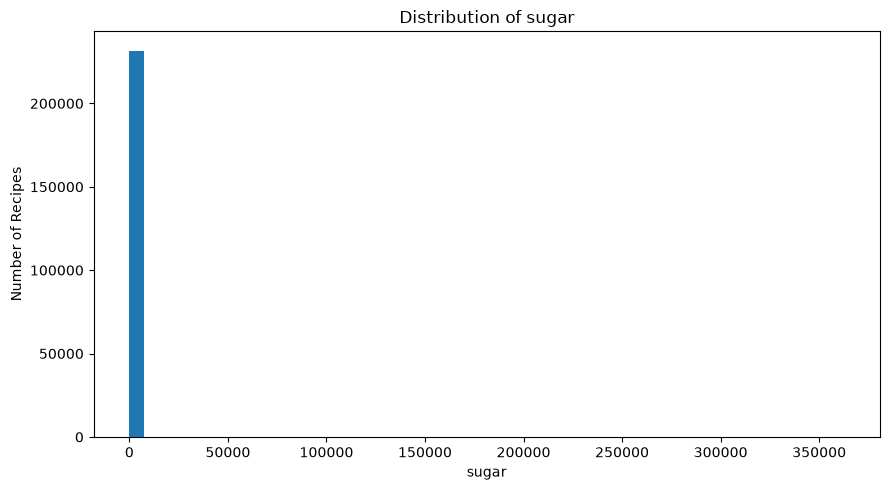

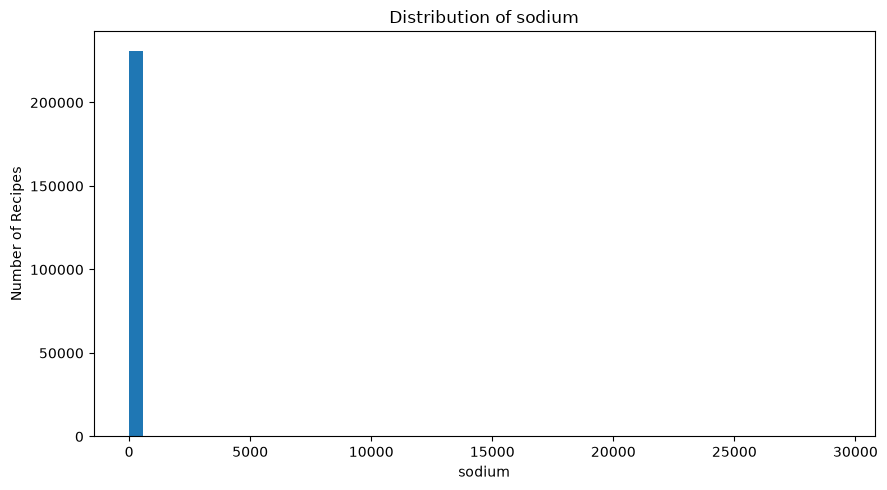

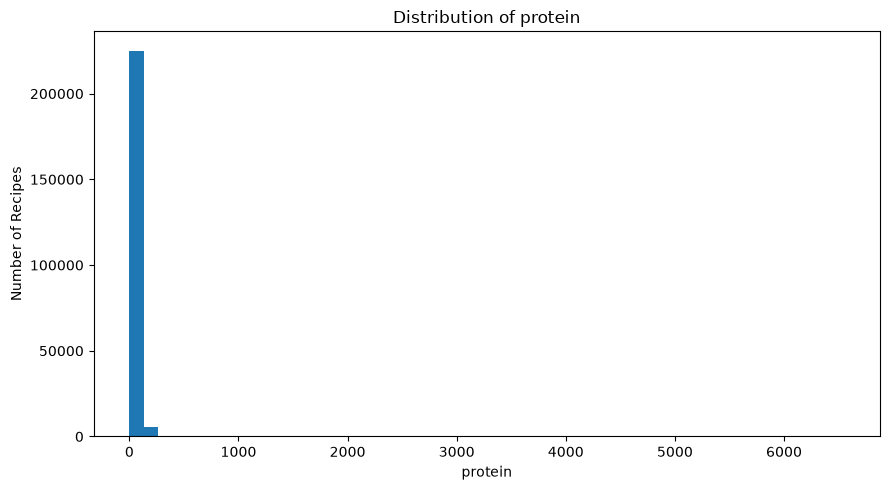

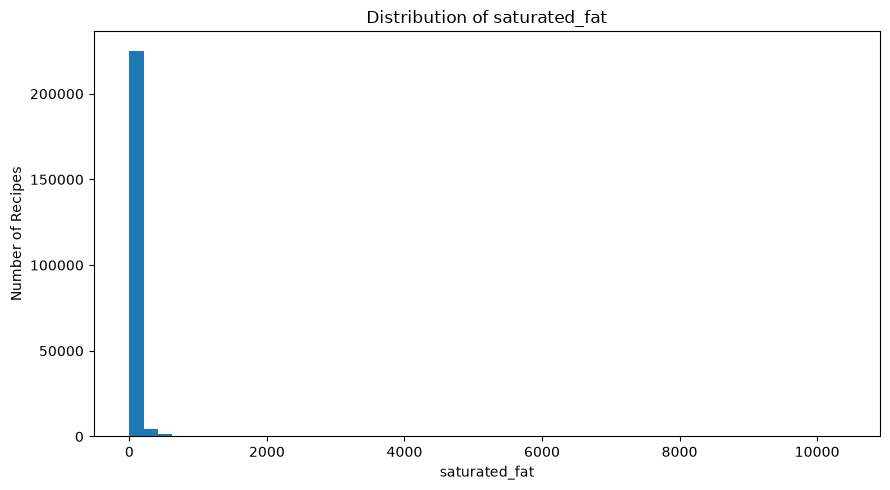

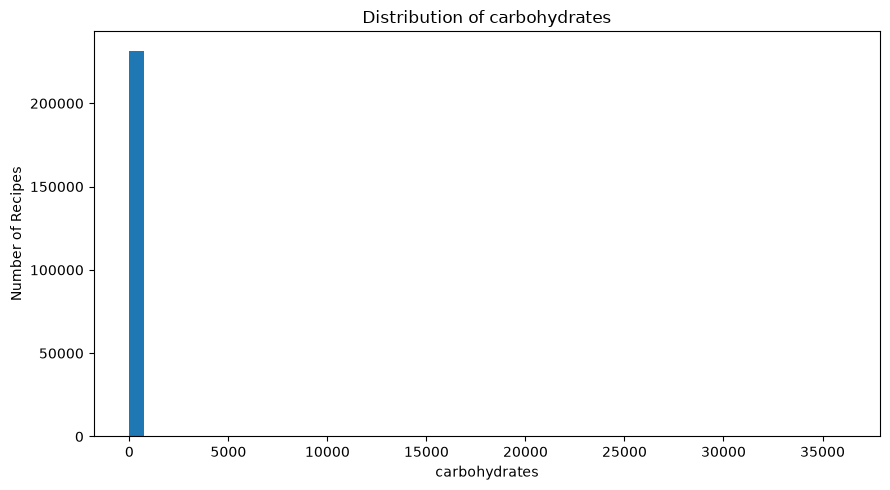

In [76]:
for column in nutrition_columns:
    plt.figure(figsize=(9, 5))

    plt.hist(recipes[column].dropna(), bins=50)

    plt.xlabel(column)
    plt.ylabel("Number of Recipes")
    plt.title(f"Distribution of {column}")

    plt.tight_layout()
    plt.show()

In [77]:
outlier_summary = []

for column in nutrition_columns:
    Q1 = recipes[column].quantile(0.25)
    Q3 = recipes[column].quantile(0.75)

    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    outliers = (recipes[column] < lower) | (recipes[column] > upper)

    outlier_summary.append(
        {
            "nutrient": column,
            "Q1": Q1,
            "Q3": Q3,
            "IQR": IQR,
            "lower_bound": lower,
            "upper_bound": upper,
            "outlier_count": outliers.sum(),
            "outlier_percentage": outliers.mean() * 100,
        }
    )

outlier_summary = pd.DataFrame(outlier_summary)

outlier_summary

,nutrient,Q1,Q3,IQR,lower_bound,upper_bound,outlier_count,outlier_percentage
0,calories,174.4,519.7,345.3,-343.55,1037.65,15737,6.793820
1,total_fat,8.0,41.0,33.0,-41.50,90.50,16265,7.021762
2,sugar,9.0,68.0,59.0,-79.50,156.50,23780,10.266063
3,sodium,5.0,33.0,28.0,-37.00,75.00,15919,6.872391
4,protein,7.0,51.0,44.0,-59.00,117.00,9141,3.946261
5,saturated_fat,7.0,52.0,45.0,-60.50,119.50,16462,7.106809
6,carbohydrates,4.0,16.0,12.0,-14.00,34.00,15559,6.716975


In [78]:
for column in nutrition_columns:
    print("\n" + "=" * 70)
    print(f"Highest values for: {column}")
    print("=" * 70)

    display(
        recipes[["id", "name", column, "ingredients"]].sort_values(column, ascending=False).head(10)
    )


Highest values for: calories


,id,name,calories,ingredients
209453,193435,tennessee moonshine,434360.2,"['cornmeal', 'natural bran', 'sugar', 'yeast', 'water']"
70467,227470,deep fried prime rib,101614.7,"['boneless rib-eye roast', 'peanut oil', 'ground rosemary', 'kosher salt', 'fresh ground black p..."
165504,392286,powdered hot cocoa mix,45609.0,"['dry milk', 'nestles quik', 'powdered sugar', 'cremora']"
137181,82848,mmmmmmmmilky way cake,44239.8,"['yellow cake mix', 'butter', 'water', 'eggs', 'milky way bars', 'evaporated milk']"
34023,18330,caledonian wedding cake,43924.6,"['raisins', 'currants', 'figs', 'sweet almonds', 'candied peel', 'brown sugar', 'flour', 'butter..."
141997,75591,my mercy strawberry cake,42951.6,"['duncan hines butter cake mix', 'crisco cooking oil', 'buttermilk', 'sugar', 'eggs', 'cool whip..."
78689,48363,easy easy friendship cake,40159.2,"['duncan hines butter cake mix', 'instant vanilla pudding', 'oil', 'water', 'cream sherry', 'pec..."
182816,59776,scott hibb s amazing whiskey grilled baby back ribs,38680.1,"['baby back rib racks', 'fresh coarse ground black pepper', 'ground red chili pepper', 'vegetabl..."
199615,93481,steph s pork riblets,38662.3,"['beef broth', 'soy sauce', 'brown sugar', 'pork riblets', 'italian dressing', 'ginger', 'dijon-..."
139058,319406,moonshine easy,36188.8,"['cornmeal', 'sugar', 'water', 'yeast']"



Highest values for: total_fat


,id,name,total_fat,ingredients
70467,227470,deep fried prime rib,17183.0,"['boneless rib-eye roast', 'peanut oil', 'ground rosemary', 'kosher salt', 'fresh ground black p..."
199615,93481,steph s pork riblets,4331.0,"['beef broth', 'soy sauce', 'brown sugar', 'pork riblets', 'italian dressing', 'ginger', 'dijon-..."
182816,59776,scott hibb s amazing whiskey grilled baby back ribs,4317.0,"['baby back rib racks', 'fresh coarse ground black pepper', 'ground red chili pepper', 'vegetabl..."
56433,500039,coffee glazed doughnuts,3464.0,"['active dry yeast', 'warm water', 'all-purpose flour', 'whole milk', 'unsalted butter', 'egg yo..."
165504,392286,powdered hot cocoa mix,3379.0,"['dry milk', 'nestles quik', 'powdered sugar', 'cremora']"
84023,260961,finger licking sticky juicy ribs,3229.0,"['pork back ribs', 'lager beer', 'barbecue sauce', 'soya sauce', 'maple syrup', 'lemon, juice an..."
164719,32152,potato crumble,3105.0,"['potatoes', 'butter', 'spring onions', 'garlic', 'milk', 'breadcrumbs', 'cheese', 'parsley']"
102405,256795,harold s florentine salad dressing,3072.0,"['lemon juice', 'garlic powder', 'onions', 'cayenne pepper', 'sugar', 'salt', 'canola oil']"
134453,232495,mexican ojarascas cookies,3021.0,"['flour', 'sugar', 'cinnamon', 'cornstarch', 'baking powder', 'salt', 'shortening', 'lard', 'wat..."
219494,313271,ultimate coconut cake ii,2899.0,"['unsalted butter', 'sugar', 'eggs', 'all-purpose flour', 'baking powder', 'salt', 'heavy cream'..."



Highest values for: sugar


...

,id,name,protein,ingredients
199615,93481,steph s pork riblets,6552.0,"['beef broth', 'soy sauce', 'brown sugar', 'pork riblets', 'italian dressing', 'ginger', 'dijon-..."
182816,59776,scott hibb s amazing whiskey grilled baby back ribs,6540.0,"['baby back rib racks', 'fresh coarse ground black pepper', 'ground red chili pepper', 'vegetabl..."
84023,260961,finger licking sticky juicy ribs,4909.0,"['pork back ribs', 'lager beer', 'barbecue sauce', 'soya sauce', 'maple syrup', 'lemon, juice an..."
165504,392286,powdered hot cocoa mix,4356.0,"['dry milk', 'nestles quik', 'powdered sugar', 'cremora']"
95462,101471,grandmag s baked christmas ham,4213.0,"['smoked ham', 'pineapple slices', 'maraschino cherries', 'brown sugar', 'whole cloves', 'honey'..."
209453,193435,tennessee moonshine,3961.0,"['cornmeal', 'natural bran', 'sugar', 'yeast', 'water']"
4252,338356,alternate honey barbecue sauce with riblets applebee s copycat,3605.0,"['ketchup', 'corn syrup', 'honey', 'apple cider vinegar', 'water', 'molasses', 'dry mustard', 'g..."
158521,139292,perfect turkey,3351.0,"['turkey', 'kosher salt', 'butter', 'onions', 'carrots', 'celery', 'fresh thyme', 'bay leaf', 'd..."
107215,250949,honey barbecue riblets applebee s,3268.0,"['pork riblets', 'barbecue sauce', 'water', 'liquid smoke', 'garlic cloves', 'salt and pepper']"
14283,77876,baked glazed ham,3156.0,"['smoked ham', 'brown sugar', 'pineapple slices', 'pineapple juice', 'honey', 'maraschino cherry..."



Highest values for: saturated_fat


,id,name,saturated_fat,ingredients
70467,227470,deep fried prime rib,10395.0,"['boneless rib-eye roast', 'peanut oil', 'ground rosemary', 'kosher salt', 'fresh ground black p..."
165504,392286,powdered hot cocoa mix,6875.0,"['dry milk', 'nestles quik', 'powdered sugar', 'cremora']"
164719,32152,potato crumble,6385.0,"['potatoes', 'butter', 'spring onions', 'garlic', 'milk', 'breadcrumbs', 'cheese', 'parsley']"
219494,313271,ultimate coconut cake ii,6269.0,"['unsalted butter', 'sugar', 'eggs', 'all-purpose flour', 'baking powder', 'salt', 'heavy cream'..."
199615,93481,steph s pork riblets,4969.0,"['beef broth', 'soy sauce', 'brown sugar', 'pork riblets', 'italian dressing', 'ginger', 'dijon-..."
182816,59776,scott hibb s amazing whiskey grilled baby back ribs,4960.0,"['baby back rib racks', 'fresh coarse ground black pepper', 'ground red chili pepper', 'vegetabl..."
34023,18330,caledonian wedding cake,4941.0,"['raisins', 'currants', 'figs', 'sweet almonds', 'candied peel', 'brown sugar', 'flour', 'butter..."
212993,394520,this is the real hooters wing sauce for the hot flavor trust me,4610.0,"['butter', 'pepper sauce', 'ground red pepper']"
55796,45389,coconut macaroons,4209.0,"['unsweetened coconut', 'sugar', 'extra large egg whites', 'table salt', 'honey', 'vanilla', 'al..."
154459,31130,patience coconut cake,3730.0,"['sour cream', 'coconut', 'powdered sugar', 'cool whip', 'white cake mix', 'egg whites', 'oil', ..."



Highest values for: carbohydrates


,id,name,carbohydrates,ingredients
209453,193435,tennessee moonshine,36098.0,"['cornmeal', 'natural bran', 'sugar', 'yeast', 'water']"
139058,319406,moonshine easy,3007.0,"['cornmeal', 'sugar', 'water', 'yeast']"
137181,82848,mmmmmmmmilky way cake,2565.0,"['yellow cake mix', 'butter', 'water', 'eggs', 'milky way bars', 'evaporated milk']"
141997,75591,my mercy strawberry cake,2315.0,"['duncan hines butter cake mix', 'crisco cooking oil', 'buttermilk', 'sugar', 'eggs', 'cool whip..."
78689,48363,easy easy friendship cake,2275.0,"['duncan hines butter cake mix', 'instant vanilla pudding', 'oil', 'water', 'cream sherry', 'pec..."
34023,18330,caledonian wedding cake,2233.0,"['raisins', 'currants', 'figs', 'sweet almonds', 'candied peel', 'brown sugar', 'flour', 'butter..."
105817,533590,hocus pocus cottage cake,1554.0,"['sugar', 'milk', 'vegetable oil', 'eggs', 'vanilla extract', 'all-purpose flour', 'unsweetened ..."
107018,386564,homesteader s fireweed honey,1511.0,"['red clover blossoms', 'white clover blossoms', 'fireweed blossoms', 'alum', 'sugar', 'boiling ..."
165504,392286,powdered hot cocoa mix,1453.0,"['dry milk', 'nestles quik', 'powdered sugar', 'cremora']"
95612,535853,granny jones secret salty sweet biscuit recipe,1440.0,"['flour', 'water', 'salt', 'sugar', 'butter']"


In [79]:
nutrition_corr = recipes[nutrition_columns].corr()

nutrition_corr

,calories,total_fat,sugar,sodium,protein,saturated_fat,carbohydrates
calories,1.000000,0.600259,0.864306,0.170535,0.486858,0.548207,0.904274
total_fat,0.600259,1.000000,0.164644,0.155745,0.509336,0.870711,0.215954
sugar,0.864306,0.164644,1.000000,0.084418,0.186464,0.166705,0.981260
sodium,0.170535,0.155745,0.084418,1.000000,0.225052,0.144746,0.110883
protein,0.486858,0.509336,0.186464,0.225052,1.000000,0.491322,0.238414
saturated_fat,0.548207,0.870711,0.166705,0.144746,0.491322,1.000000,0.214146
carbohydrates,0.904274,0.215954,0.981260,0.110883,0.238414,0.214146,1.000000


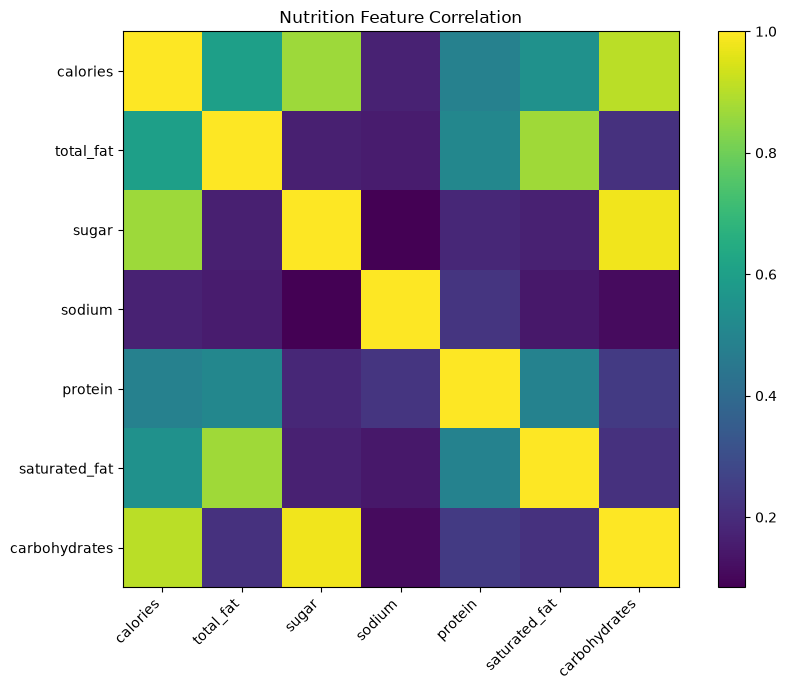

In [80]:
plt.figure(figsize=(9, 7))

plt.imshow(nutrition_corr, interpolation="none")

plt.xticks(range(len(nutrition_columns)), nutrition_columns, rotation=45, ha="right")

plt.yticks(range(len(nutrition_columns)), nutrition_columns)

plt.colorbar()

plt.title("Nutrition Feature Correlation")

plt.tight_layout()
plt.show()

In [81]:
recipes["ingredients_list"]

0                             [winter squash, mexican seasoning, mixed spice, honey, butter, olive oil, salt]
1                                  [prepared pizza crust, sausage patty, eggs, milk, salt and pepper, cheese]
2         [ground beef, yellow onions, diced tomatoes, tomato paste, tomato soup, rotel tomatoes, kidney b...
3         [spreadable cheese with garlic and herbs, new potatoes, shallots, parsley, tarragon, olive oil, ...
4              [tomato juice, apple cider vinegar, sugar, salt, pepper, clove oil, cinnamon oil, dry mustard]
                                                         ...                                                 
231632    [celery, onion, green sweet pepper, garlic cloves, olive oil, cooked ham, paprika, sugar, dry mu...
231633    [paprika, salt, garlic powder, onion powder, dried basil, dried oregano, dried tarragon, dried t...
231634    [hard-cooked eggs, mayonnaise, dijon mustard, salt-free cajun seasoning, tabasco sauce, salt, bl...
231635    

In [82]:
ingredient_counts = recipes["ingredients_list"].apply(len)

print(ingredient_counts.describe())

count    231637.000000
mean          9.051153
std           3.734796
min           1.000000
25%           6.000000
50%           9.000000
75%          11.000000
max          43.000000
Name: ingredients_list, dtype: float64


In [83]:
comparison = pd.DataFrame(
    {"n_ingredients_column": recipes["n_ingredients"], "parsed_ingredient_count": ingredient_counts}
)

comparison["difference"] = (
    comparison["n_ingredients_column"] - comparison["parsed_ingredient_count"]
)

comparison.head(20)

,n_ingredients_column,parsed_ingredient_count,difference
0,7,7,0
1,6,6,0
2,13,13,0
3,11,11,0
4,8,8,0
5,4,4,0
6,9,9,0
7,22,22,0
8,6,6,0
9,9,9,0


In [84]:
print("Recipes where counts match:", (comparison["difference"] == 0).sum())

print("Recipes where counts differ:", (comparison["difference"] != 0).sum())

Recipes where counts match: 231637
Recipes where counts differ: 0


In [85]:
print("Total unique raw ingredient strings:", len(ingredient_counter))

Total unique raw ingredient strings: 14942


In [86]:
unique_ingredients = (
    pd.DataFrame(ingredient_counter.items(), columns=["ingredient", "recipe_count"])
    .sort_values("recipe_count", ascending=False)
    .reset_index(drop=True)
)

unique_ingredients.head(50)

,ingredient,recipe_count
0,salt,85746
1,butter,54975
2,sugar,44535
3,onion,39065
4,water,34914
5,eggs,33761
6,olive oil,32822
7,flour,26266
8,milk,25786
9,garlic cloves,25748


In [87]:
ingredient_frequency_summary = unique_ingredients["recipe_count"].describe()

ingredient_frequency_summary

count    14942.000000
mean       140.314683
std       1341.349585
min          1.000000
25%          2.000000
50%          5.000000
75%         28.000000
max      85746.000000
Name: recipe_count, dtype: float64

In [88]:
print("Ingredients appearing in only 1 recipe:", (unique_ingredients["recipe_count"] == 1).sum())

print(
    "Ingredients appearing in 2 or fewer recipes:", (unique_ingredients["recipe_count"] <= 2).sum()
)

Ingredients appearing in only 1 recipe: 3546
Ingredients appearing in 2 or fewer recipes: 5217


In [89]:
ingredient_search_terms = [
    "garlic",
    "onion",
    "egg",
    "flour",
    "milk",
    "oil",
    "tomato",
    "chicken",
    "rice",
    "salt",
]

for term in ingredient_search_terms:
    matches = unique_ingredients[
        unique_ingredients["ingredient"].str.contains(term, case=False, na=False)
    ]

    print("\n" + "=" * 60)
    print(f"Ingredients containing '{term}'")
    print("=" * 60)

    display(matches.head(30))


Ingredients containing 'garlic'


,ingredient,recipe_count
9,garlic cloves,25748
12,garlic,18087
26,garlic powder,10887
32,garlic clove,9779
129,garlic salt,2636
330,fresh garlic,951
487,minced garlic cloves,619
741,fresh garlic cloves,360
846,minced garlic clove,296
998,chili-garlic sauce,235



Ingredients containing 'onion'


,ingredient,recipe_count
3,onion,39065
30,onions,9872
57,green onions,5814
58,red onion,5777
62,green onion,5585
93,onion powder,3598
146,yellow onion,2297
254,white onion,1311
259,sweet onion,1286
293,red onions,1096



Ingredients containing 'egg'


...

,ingredient,recipe_count
39,chicken broth,7963
76,chicken stock,4352
83,boneless skinless chicken breasts,3994
120,chicken breasts,2793
164,chicken,2115
180,cooked chicken,1931
197,boneless skinless chicken breast halves,1753
221,cream of chicken soup,1531
271,boneless skinless chicken breast,1236
283,low sodium chicken broth,1166



Ingredients containing 'rice'


,ingredient,recipe_count
211,cooked rice,1589
227,rice vinegar,1519
235,rice,1463
400,rice wine vinegar,736
453,brown rice,659
464,long grain rice,645
504,white rice,598
525,basmati rice,572
645,cooked brown rice,431
655,arborio rice,416



Ingredients containing 'salt'


,ingredient,recipe_count
0,salt,85746
16,salt and pepper,15415
35,unsalted butter,8935
63,kosher salt,5583
106,sea salt,3138
108,salt & freshly ground black pepper,3123
129,garlic salt,2636
148,seasoning salt,2261
157,salt & pepper,2156
294,coarse salt,1095


In [90]:
sample_ingredients = recipes["ingredients_list"].sample(30, random_state=42)

for i, ingredient_list in enumerate(sample_ingredients):
    print(f"\nRecipe sample {i + 1}")

    for ingredient in ingredient_list:
        print("  -", ingredient)


Recipe sample 1
  - crabmeat
  - cream cheese
  - green onions
  - garlic salt
  - refrigerated crescent dinner rolls
  - egg yolk
  - water
  - sesame seeds
  - sweet and sour sauce

Recipe sample 2
  - garbanzo beans
  - black beans
  - onion
  - ginger paste
  - mild curry powder
  - dried cilantro
  - lemon juice
  - diced tomatoes
  - creamed corn
  - cooked brown rice
  - rice cakes
  - raisins

Recipe sample 3
  - olive oil
  - red onion
  - light brown sugar
  - balsamic vinegar
  - steaks

Recipe sample 4
  - pork tenderloin
  - soy sauce
  - hoisin sauce
  - rice wine
  - hot chili paste
  - tomato ketchup
  - garlic
  - fresh gingerroot
  - green onion
  - fresh cilantro

Recipe sample 5
  - mixed baby greens
  - oranges
  - grapefruit
  - avocado
  - olive oil
  - balsamic vinegar
  - kosher salt
  - fresh ground pepper

Recipe sample 6
  - sugar
  - all-purpose flour
  - salt
  - milk
  - unsalted butter
  - vanilla extract

Recipe sample 7
  - eggs
  - sour cream
  - moz

In [91]:
measurement_words = [
    "cup",
    "cups",
    "tablespoon",
    "tablespoons",
    "tbsp",
    "teaspoon",
    "teaspoons",
    "tsp",
    "ounce",
    "ounces",
    "oz",
    "pound",
    "pounds",
    "lb",
    "lbs",
    "gram",
    "grams",
    "kg",
    "ml",
    "liter",
    "litre",
]

measurement_counts = {}

for word in measurement_words:
    count = sum(
        word in ingredient.lower()
        for ingredient_list in recipes["ingredients_list"]
        for ingredient in ingredient_list
    )

    measurement_counts[word] = count

measurement_counts_df = pd.DataFrame(
    measurement_counts.items(), columns=["measurement", "occurrence_count"]
).sort_values("occurrence_count", ascending=False)

measurement_counts_df

,measurement,occurrence_count
10,oz,19347
13,lb,2754
0,cup,247
1,cups,182
11,pound,148
14,lbs,135
15,gram,74
18,ml,1
2,tablespoon,0
4,tbsp,0


In [92]:
import re

numeric_ingredients = []

for ingredient_list in recipes["ingredients_list"]:
    for ingredient in ingredient_list:
        if re.search(r"\d", ingredient):
            numeric_ingredients.append(ingredient)

numeric_ingredients = pd.Series(numeric_ingredients).drop_duplicates()

print("Unique ingredient strings containing numbers:", len(numeric_ingredients))

numeric_ingredients.head(100).to_list()

Unique ingredient strings containing numbers: 188


['a.1. original sauce',
 '2% low-fat milk',
 'v8 vegetable juice',
 '98% fat-free cream of mushroom soup',
 '1% low-fat milk',
 '2% fat cottage cheese',
 '7-up soda',
 '10 bean soup mix',
 '15 bean soup mix',
 '15 bean mix',
 'maggi 2-minute noodles',
 'kraft 100% parmesan cheese',
 '80% lean ground beef',
 '12-inch pizza crust',
 'unbaked 9-inch pie shell',
 'licor 43',
 '98% fat-free cream of chicken soup',
 'heinz 57 steak sauce',
 '8-inch flour tortillas',
 '7-up',
 '2% cheddar cheese',
 'evaporated 2% milk',
 '10-inch flour tortillas',
 '9-inch pie shells',
 '9" unbaked pie shell',
 'ale 8 soft drink',
 '85% lean ground beef',
 '35% cream',
 '95% lean ground beef',
 '10-inch  deep dish pie crust',
 '9-inch graham cracker crust',
 '9 in.baked pastry shell',
 'unbaked 8-inch pie shell',
 '9-inch baked pie crust',
 'unbaked 9-inch pie crust',
 '9 inch pie shell',
 'low-sodium v8 juice',
 '3-cheese gourmet cheddar blend cheese',
 'unbaked 10-inch pie shell',
 '2% buttermilk',
 '9 in. 

In [93]:
foodcom_stage3_summary = pd.DataFrame(
    {
        "metric": [
            "Total recipes",
            "Total unique raw ingredients",
            "Median ingredients per recipe",
            "Mean ingredients per recipe",
            "Maximum ingredients per recipe",
            "Recipes with nutrition vector length 7",
            "Recipes with missing nutrition vectors",
            "Recipes with descriptions",
            "Recipes with identified cuisine",
        ],
        "value": [
            len(recipes),
            len(unique_ingredients),
            recipes["n_ingredients"].median(),
            recipes["n_ingredients"].mean(),
            recipes["n_ingredients"].max(),
            (nutrition_lengths == 7).sum(),
            (nutrition_lengths == 0).sum(),
            recipes["description"].notna().sum(),
            recipes_with_cuisine.sum(),
        ],
    }
)

foodcom_stage3_summary

,metric,value
0,Total recipes,231637.000000
1,Total unique raw ingredients,14942.000000
2,Median ingredients per recipe,9.000000
3,Mean ingredients per recipe,9.051153
4,Maximum ingredients per recipe,43.000000
5,Recipes with nutrition vector length 7,231637.000000
6,Recipes with missing nutrition vectors,0.000000
7,Recipes with descriptions,226658.000000
8,Recipes with identified cuisine,68631.000000


In [94]:
nutrition_lengths.value_counts().sort_index()

nutrition_list
7    231637
Name: count, dtype: int64

In [95]:
nutrition_summary

,count,mean,std,min,25%,50%,75%,max
calories,231637.0,473.942425,1189.711374,0.0,174.4,313.4,519.7,434360.2
total_fat,231637.0,36.080700,77.798840,0.0,8.0,20.0,41.0,17183.0
sugar,231637.0,84.296865,800.080897,0.0,9.0,25.0,68.0,362729.0
sodium,231637.0,30.147485,131.961589,0.0,5.0,14.0,33.0,29338.0
protein,231637.0,34.681860,58.472480,0.0,7.0,18.0,51.0,6552.0
saturated_fat,231637.0,45.589150,98.235758,0.0,7.0,23.0,52.0,10395.0
carbohydrates,231637.0,15.560403,81.824560,0.0,4.0,9.0,16.0,36098.0


In [96]:
nutrition_missing

,missing_count,missing_percentage
calories,0,0.0
total_fat,0,0.0
sugar,0,0.0
sodium,0,0.0
protein,0,0.0
saturated_fat,0,0.0
carbohydrates,0,0.0


In [97]:
zero_summary

,zero_count,zero_percentage
calories,53,0.022881
total_fat,16770,7.239776
sugar,10322,4.456110
sodium,19841,8.565557
protein,9837,4.246731
saturated_fat,19732,8.518501
carbohydrates,13068,5.641586


In [98]:
outlier_summary

,nutrient,Q1,Q3,IQR,lower_bound,upper_bound,outlier_count,outlier_percentage
0,calories,174.4,519.7,345.3,-343.55,1037.65,15737,6.793820
1,total_fat,8.0,41.0,33.0,-41.50,90.50,16265,7.021762
2,sugar,9.0,68.0,59.0,-79.50,156.50,23780,10.266063
3,sodium,5.0,33.0,28.0,-37.00,75.00,15919,6.872391
4,protein,7.0,51.0,44.0,-59.00,117.00,9141,3.946261
5,saturated_fat,7.0,52.0,45.0,-60.50,119.50,16462,7.106809
6,carbohydrates,4.0,16.0,12.0,-14.00,34.00,15559,6.716975


In [99]:
print("Total unique raw ingredient strings:", len(ingredient_counter))

Total unique raw ingredient strings: 14942


In [100]:
comparison["difference"].value_counts()

difference
0    231637
Name: count, dtype: int64

In [102]:
# Load PP_recipes
pp_recipes = pd.read_csv(os.path.join(DATA_PATH, "PP_recipes.csv"))

print("Shape:", pp_recipes.shape)

Shape: (178265, 8)


In [103]:
pp_recipes.head()

,id,i,name_tokens,ingredient_tokens,steps_tokens,techniques,calorie_level,ingredient_ids
0,424415,23,"[40480, 37229, 2911, 1019, 249, 6878, 6878, 2839, 1781, 40481]","[[2911, 1019, 249, 6878], [1353], [6953], [15341, 3261], [2056, 857, 643, 1631, 20480]]","[40480, 40482, 21662, 481, 6878, 500, 246, 1614, 1911, 10757, 240, 674, 9933, 8400, 40478, 40482...","[0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,...",0,"[389, 7655, 6270, 1527, 3406]"
1,146223,96900,"[40480, 18376, 7056, 246, 1531, 2032, 40481]","[[17918], [25916], [2507, 6444], [8467, 1179], [8780], [6812], [4370, 2653, 18376], [2654, 5581,...","[40480, 40482, 729, 2525, 10906, 485, 43, 8393, 40478, 40482, 23667, 17918, 240, 25916, 240, 250...","[1, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0,...",0,"[2683, 4969, 800, 5298, 840, 2499, 6632, 7022, 1511, 3248, 4964, 6270]"
2,312329,120056,"[40480, 21044, 16954, 8294, 556, 10837, 40481]","[[5867, 24176], [1353], [6953], [1301, 11332], [21453, 8361], [25845, 8111, 11332], [23488, 8361...","[40480, 40482, 8240, 481, 24176, 296, 1353, 666, 246, 1719, 5082, 40478, 40482, 4846, 481, 21298...","[0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0,...",1,"[1257, 7655, 6270, 590, 5024, 1119, 4883, 6696, 7946, 5648, 7239, 7705, 7594, 1168, 2683]"
3,74301,168258,"[40480, 10025, 31156, 40481]","[[1270, 1645, 28447], [21601], [27952, 29471, 484], [31843], [6821], [9514, 4914], [10444], [692...","[40480, 40482, 5539, 21601, 1073, 903, 2324, 40478, 40482, 9933, 481, 4739, 488, 9467, 500, 2795...","[1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,...",0,"[7940, 3609, 7060, 6265, 1170, 6654, 5003, 3561]"
4,76272,109030,"[40480, 17841, 252, 782, 2373, 1641, 2373, 252, 40481]","[[1430, 11434], [1430, 17027], [1615, 23, 695, 2338, 6821], [13134, 2555, 29273, 9410]]","[40480, 40482, 14046, 1430, 11434, 488, 17027, 1073, 903, 2324, 40478, 40482, 9933, 811, 4739, 4...","[0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,...",0,"[3484, 6324, 7594, 243]"


In [104]:
print("Number of rows:", pp_recipes.shape[0])
print("Number of columns:", pp_recipes.shape[1])

print("\nColumns:")
print(pp_recipes.columns.tolist())

print("\nData types:")
pp_recipes.info()

Number of rows: 178265
Number of columns: 8

Columns:
['id', 'i', 'name_tokens', 'ingredient_tokens', 'steps_tokens', 'techniques', 'calorie_level', 'ingredient_ids']

Data types:
<class 'pandas.DataFrame'>
RangeIndex: 178265 entries, 0 to 178264
Data columns (total 8 columns):
 #   Column             Non-Null Count   Dtype
---  ------             --------------   -----
 0   id                 178265 non-null  int64
 1   i                  178265 non-null  int64
 2   name_tokens        178265 non-null  str  
 3   ingredient_tokens  178265 non-null  str  
 4   steps_tokens       178265 non-null  str  
 5   techniques         178265 non-null  str  
 6   calorie_level      178265 non-null  int64
 7   ingredient_ids     178265 non-null  str  
dtypes: int64(3), str(5)
memory usage: 10.9 MB


In [105]:
pp_missing = pd.DataFrame(
    {
        "missing_count": pp_recipes.isnull().sum(),
        "missing_percentage": pp_recipes.isnull().mean() * 100,
    }
).sort_values("missing_percentage", ascending=False)

pp_missing

,missing_count,missing_percentage
id,0,0.0
i,0,0.0
name_tokens,0,0.0
ingredient_tokens,0,0.0
steps_tokens,0,0.0
techniques,0,0.0
calorie_level,0,0.0
ingredient_ids,0,0.0


In [106]:
print("Duplicate rows:", pp_recipes.duplicated().sum())

Duplicate rows: 0


In [107]:
print("RAW_recipes shape:")
print(recipes.shape)

print("\nPP_recipes shape:")
print(pp_recipes.shape)

RAW_recipes shape:
(231637, 24)

PP_recipes shape:
(178265, 8)


In [108]:
print("RAW_recipes columns:")
print(recipes.columns.tolist())

print("\nPP_recipes columns:")
print(pp_recipes.columns.tolist())

RAW_recipes columns:
['name', 'id', 'minutes', 'contributor_id', 'submitted', 'tags', 'nutrition', 'n_steps', 'steps', 'description', 'ingredients', 'n_ingredients', 'ingredients_list', 'tags_list', 'description_length', 'cuisine_candidates', 'nutrition_list', 'calories', 'total_fat', 'sugar', 'sodium', 'protein', 'saturated_fat', 'carbohydrates']

PP_recipes columns:
['id', 'i', 'name_tokens', 'ingredient_tokens', 'steps_tokens', 'techniques', 'calorie_level', 'ingredient_ids']


In [109]:
pp_recipes.head(10).to_string()

'       id       i                                                     name_tokens                                                                                                                                                                                                                                                                                  ingredient_tokens                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                   

In [110]:
for col in pp_recipes.columns:
    print("\n" + "=" * 60)
    print("COLUMN:", col)
    print("=" * 60)
    print(pp_recipes[col].head(5).tolist())


COLUMN: id
[424415, 146223, 312329, 74301, 76272]

COLUMN: i
[23, 96900, 120056, 168258, 109030]

COLUMN: name_tokens
['[40480, 37229, 2911, 1019, 249, 6878, 6878, 2839, 1781, 40481]', '[40480, 18376, 7056, 246, 1531, 2032, 40481]', '[40480, 21044, 16954, 8294, 556, 10837, 40481]', '[40480, 10025, 31156, 40481]', '[40480, 17841, 252, 782, 2373, 1641, 2373, 252, 40481]']

COLUMN: ingredient_tokens
['[[2911, 1019, 249, 6878], [1353], [6953], [15341, 3261], [2056, 857, 643, 1631, 20480]]', '[[17918], [25916], [2507, 6444], [8467, 1179], [8780], [6812], [4370, 2653, 18376], [2654, 5581, 34904, 5940], [15341], [10848], [21447, 7869], [6953]]', '[[5867, 24176], [1353], [6953], [1301, 11332], [21453, 8361], [25845, 8111, 11332], [23488, 8361], [37754, 10734], [652, 25, 3035, 11959, 10734], [10837], [19811, 21137, 556, 20323, 15022, 296, 7, 4344, 6741], [11951, 4914], [1615, 23, 695, 2338, 6821], [2801, 30645, 4785, 6821], [17918]]', '[[1270, 1645, 28447], [21601], [27952, 29471, 484], [31843

In [111]:
print("RAW recipe IDs:", recipes["id"].nunique())

RAW recipe IDs: 231637


In [112]:
print(pp_recipes.columns.tolist())

['id', 'i', 'name_tokens', 'ingredient_tokens', 'steps_tokens', 'techniques', 'calorie_level', 'ingredient_ids']


In [113]:
if "i" in pp_recipes.columns:
    print("PP recipe IDs:", pp_recipes["i"].nunique())
    print(pp_recipes["i"].head())

PP recipe IDs: 178265
0        23
1     96900
2    120056
3    168258
4    109030
Name: i, dtype: int64


In [114]:
if "id" in pp_recipes.columns:
    print("PP recipe IDs:", pp_recipes["id"].nunique())
    print(pp_recipes["id"].head())

PP recipe IDs: 178265
0    424415
1    146223
2    312329
3     74301
4     76272
Name: id, dtype: int64


In [118]:
import os
import pickle
import sys

import pandas as pd

# 1. Alias pandas.Index to Int64Index for backward compatibility
import pandas.core.indexes.base as _base

_base.Int64Index = pd.Index
pd.Int64Index = pd.Index

# 2. Redirect the old module location to pandas.core.indexes.base
sys.modules["pandas.core.indexes.numeric"] = _base

# 3. Now load the pickle file
ingr_map_path = os.path.join(DATA_PATH, "ingr_map.pkl")

with open(ingr_map_path, "rb") as f:
    ingr_map = pickle.load(f)

print("Object type:")
print(type(ingr_map))

Object type:
<class 'pandas.DataFrame'>


In [119]:
print("Object representation:")
print(ingr_map)

Object representation:
                                                                         raw_ingr  \
0      medium heads bibb or red leaf lettuce, washed, dried* and torn into pieces   
1                                           mixed baby lettuces and spring greens   
2                                                            romaine lettuce leaf   
3                                                            iceberg lettuce leaf   
4                                                             red romaine lettuce   
...                                                                           ...   
11654                                                                    soybeans   
11655                                                                       goose   
11656                                                                      ajwain   
11657                                                                    brinjals   
11658                                     

In [120]:
print("Type:", type(ingr_map))

if hasattr(ingr_map, "shape"):
    print("Shape:", ingr_map.shape)

if hasattr(ingr_map, "columns"):
    print("Columns:", ingr_map.columns.tolist())

if hasattr(ingr_map, "index"):
    print("Index type:", type(ingr_map.index))

if hasattr(ingr_map, "head"):
    display(ingr_map.head(20))

Type: <class 'pandas.DataFrame'>
Shape: (11659, 7)
Columns: ['raw_ingr', 'raw_words', 'processed', 'len_proc', 'replaced', 'count', 'id']
Index type: <class 'pandas.Index'>


,raw_ingr,raw_words,processed,len_proc,replaced,count,id
0,"medium heads bibb or red leaf lettuce, washed, dried* and torn into pieces",13,"medium heads bibb or red leaf lettuce, washed, dried* and torn into piece",73,lettuce,4507,4308
1,mixed baby lettuces and spring greens,6,mixed baby lettuces and spring green,36,lettuce,4507,4308
2,romaine lettuce leaf,3,romaine lettuce leaf,20,lettuce,4507,4308
3,iceberg lettuce leaf,3,iceberg lettuce leaf,20,lettuce,4507,4308
4,red romaine lettuce,3,red romaine lettuce,19,lettuce,4507,4308
5,head romaine lettuce,3,head romaine lettuce,20,lettuce,4507,4308
6,curly endive lettuce,3,curly endive lettuce,20,lettuce,4507,4308
7,romaine lettuce hearts,3,romaine lettuce heart,21,lettuce,4507,4308
8,baby leaf lettuce,3,baby leaf lettuce,17,lettuce,4507,4308
9,head of lettuce,3,head of lettuce,15,lettuce,4507,4308


In [121]:
ingr_map.info()

<class 'pandas.DataFrame'>
Index: 11659 entries, 0 to 11658
Data columns (total 7 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   raw_ingr   11659 non-null  object
 1   raw_words  11659 non-null  int64 
 2   processed  11659 non-null  object
 3   len_proc   11659 non-null  int64 
 4   replaced   11659 non-null  object
 5   count      11659 non-null  int64 
 6   id         11659 non-null  int16 
dtypes: int16(1), int64(3), object(3)
memory usage: 660.4+ KB


In [122]:
display(ingr_map.head(20))

,raw_ingr,raw_words,processed,len_proc,replaced,count,id
0,"medium heads bibb or red leaf lettuce, washed, dried* and torn into pieces",13,"medium heads bibb or red leaf lettuce, washed, dried* and torn into piece",73,lettuce,4507,4308
1,mixed baby lettuces and spring greens,6,mixed baby lettuces and spring green,36,lettuce,4507,4308
2,romaine lettuce leaf,3,romaine lettuce leaf,20,lettuce,4507,4308
3,iceberg lettuce leaf,3,iceberg lettuce leaf,20,lettuce,4507,4308
4,red romaine lettuce,3,red romaine lettuce,19,lettuce,4507,4308
5,head romaine lettuce,3,head romaine lettuce,20,lettuce,4507,4308
6,curly endive lettuce,3,curly endive lettuce,20,lettuce,4507,4308
7,romaine lettuce hearts,3,romaine lettuce heart,21,lettuce,4507,4308
8,baby leaf lettuce,3,baby leaf lettuce,17,lettuce,4507,4308
9,head of lettuce,3,head of lettuce,15,lettuce,4507,4308


In [123]:
display(ingr_map.tail(20))

,raw_ingr,raw_words,processed,len_proc,replaced,count,id
11639,absinthe,1,absinthe,8,absinthe,2,17
11640,shortcakes,1,shortcake,9,shortcake,6,6469
11641,gluten,1,gluten,6,gluten,59,3287
11642,bluefish,1,bluefish,8,bluefish,3,658
11643,quatre-epices,1,quatre-epice,12,quatre-epice,2,5784
11644,rambutans,1,rambutan,8,rambutan,2,5830
11645,semolina,1,semolina,8,semolina,87,6400
11646,bresaola,1,bresaola,8,bresaola,2,737
11647,roast,1,roast,5,roast,74,6103
11648,condiments,1,condiment,9,condiment,15,1688


In [124]:
print("Shape:", ingr_map.shape)
print("Columns:", ingr_map.columns.tolist())

Shape: (11659, 7)
Columns: ['raw_ingr', 'raw_words', 'processed', 'len_proc', 'replaced', 'count', 'id']


In [125]:
ingr_map.isnull().sum()

raw_ingr     0
raw_words    0
processed    0
len_proc     0
replaced     0
count        0
id           0
dtype: int64

In [126]:
pd.DataFrame(
    {"missing_count": ingr_map.isnull().sum(), "missing_percentage": ingr_map.isnull().mean() * 100}
)

,missing_count,missing_percentage
raw_ingr,0,0.0
raw_words,0,0.0
processed,0,0.0
len_proc,0,0.0
replaced,0,0.0
count,0,0.0
id,0,0.0


In [127]:
ingr_map.columns.tolist()

['raw_ingr', 'raw_words', 'processed', 'len_proc', 'replaced', 'count', 'id']

In [128]:
display(ingr_map.sample(min(30, len(ingr_map)), random_state=42))

,raw_ingr,raw_words,processed,len_proc,replaced,count,id
3858,low-fat turkey kielbasa,3,turkey kielbasa,15,turkey kielbasa,45,7318
5688,pork butterfly steaks,3,pork butterfly steak,20,pork butterfly steak,5,5573
8834,dried chilies,2,dried chily,11,dried chily,60,2239
9147,ground coriander,2,ground coriander,16,ground coriander,1555,3500
6398,cinnamon baking chips,3,cinnamon baking chip,20,cinnamon baking chip,48,1514
8468,pasta,1,pastum,6,pastum,977,5219
9559,butternut squash,2,butternut squash,16,butternut squash,672,875
8690,candy cane,2,candy cane,10,candy cane,65,955
4475,firm tofu,2,firm tofu,9,firm tofu,636,2643
5023,dried fine herbs,3,dried fine herb,15,dried fine herb,6,2264


In [129]:
print("Number of unique raw Food.com ingredients:")
print(len(unique_ingredients))

Number of unique raw Food.com ingredients:
14942


In [130]:
print("\nExample Food.com ingredients:")
print(unique_ingredients["ingredient"].head(30).tolist())


Example Food.com ingredients:
['salt', 'butter', 'sugar', 'onion', 'water', 'eggs', 'olive oil', 'flour', 'milk', 'garlic cloves', 'pepper', 'brown sugar', 'garlic', 'all-purpose flour', 'baking powder', 'egg', 'salt and pepper', 'parmesan cheese', 'lemon juice', 'baking soda', 'vegetable oil', 'vanilla', 'black pepper', 'cinnamon', 'tomatoes', 'sour cream', 'garlic powder', 'vanilla extract', 'oil', 'honey']


In [131]:
for col in pp_recipes.columns:
    print(col, "->", pp_recipes[col].iloc[0])

id -> 424415
i -> 23
name_tokens -> [40480, 37229, 2911, 1019, 249, 6878, 6878, 2839, 1781, 40481]
ingredient_tokens -> [[2911, 1019, 249, 6878], [1353], [6953], [15341, 3261], [2056, 857, 643, 1631, 20480]]
steps_tokens -> [40480, 40482, 21662, 481, 6878, 500, 246, 1614, 1911, 10757, 240, 674, 9933, 8400, 40478, 40482, 1082, 589, 16126, 500, 481, 6878, 2839, 1781, 5024, 240, 488, 13770, 485, 23667, 40478, 40482, 1233, 481, 4165, 562, 481, 5186, 1454, 6878, 7213, 40478, 40482, 669, 481, 4165, 10230, 485, 256, 1178, 2107, 256, 240, 1233, 246, 17764, 562, 7648, 1571, 40478, 40482, 861, 7648, 1571, 240, 25690, 6878, 556, 481, 4438, 17080, 522, 246, 3602, 9082, 40478, 40482, 4103, 597, 240, 522, 1357, 504, 256, 1178, 2107, 256, 562, 609, 485, 282, 1808, 40478, 40481]
techniques -> [0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0]
calorie_level -> 0
ingredient_ids -> 

In [132]:
[col for col in pp_recipes.columns if any(word in col.lower() for word in ["ingr", "ingredient"])]

['ingredient_tokens', 'ingredient_ids']

In [133]:
print(pp_recipes.shape)
print(pp_recipes.columns.tolist())

(178265, 8)
['id', 'i', 'name_tokens', 'ingredient_tokens', 'steps_tokens', 'techniques', 'calorie_level', 'ingredient_ids']


In [134]:
pp_recipes.head()

,id,i,name_tokens,ingredient_tokens,steps_tokens,techniques,calorie_level,ingredient_ids
0,424415,23,"[40480, 37229, 2911, 1019, 249, 6878, 6878, 2839, 1781, 40481]","[[2911, 1019, 249, 6878], [1353], [6953], [15341, 3261], [2056, 857, 643, 1631, 20480]]","[40480, 40482, 21662, 481, 6878, 500, 246, 1614, 1911, 10757, 240, 674, 9933, 8400, 40478, 40482...","[0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,...",0,"[389, 7655, 6270, 1527, 3406]"
1,146223,96900,"[40480, 18376, 7056, 246, 1531, 2032, 40481]","[[17918], [25916], [2507, 6444], [8467, 1179], [8780], [6812], [4370, 2653, 18376], [2654, 5581,...","[40480, 40482, 729, 2525, 10906, 485, 43, 8393, 40478, 40482, 23667, 17918, 240, 25916, 240, 250...","[1, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0,...",0,"[2683, 4969, 800, 5298, 840, 2499, 6632, 7022, 1511, 3248, 4964, 6270]"
2,312329,120056,"[40480, 21044, 16954, 8294, 556, 10837, 40481]","[[5867, 24176], [1353], [6953], [1301, 11332], [21453, 8361], [25845, 8111, 11332], [23488, 8361...","[40480, 40482, 8240, 481, 24176, 296, 1353, 666, 246, 1719, 5082, 40478, 40482, 4846, 481, 21298...","[0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0,...",1,"[1257, 7655, 6270, 590, 5024, 1119, 4883, 6696, 7946, 5648, 7239, 7705, 7594, 1168, 2683]"
3,74301,168258,"[40480, 10025, 31156, 40481]","[[1270, 1645, 28447], [21601], [27952, 29471, 484], [31843], [6821], [9514, 4914], [10444], [692...","[40480, 40482, 5539, 21601, 1073, 903, 2324, 40478, 40482, 9933, 481, 4739, 488, 9467, 500, 2795...","[1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,...",0,"[7940, 3609, 7060, 6265, 1170, 6654, 5003, 3561]"
4,76272,109030,"[40480, 17841, 252, 782, 2373, 1641, 2373, 252, 40481]","[[1430, 11434], [1430, 17027], [1615, 23, 695, 2338, 6821], [13134, 2555, 29273, 9410]]","[40480, 40482, 14046, 1430, 11434, 488, 17027, 1073, 903, 2324, 40478, 40482, 9933, 811, 4739, 4...","[0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,...",0,"[3484, 6324, 7594, 243]"


In [135]:
print(type(ingr_map))
print(ingr_map.shape if hasattr(ingr_map, "shape") else "No shape")

<class 'pandas.DataFrame'>
(11659, 7)


In [136]:
print(ingr_map.columns.tolist() if hasattr(ingr_map, "columns") else "No columns")

['raw_ingr', 'raw_words', 'processed', 'len_proc', 'replaced', 'count', 'id']


In [137]:
display(ingr_map.head(20))

,raw_ingr,raw_words,processed,len_proc,replaced,count,id
0,"medium heads bibb or red leaf lettuce, washed, dried* and torn into pieces",13,"medium heads bibb or red leaf lettuce, washed, dried* and torn into piece",73,lettuce,4507,4308
1,mixed baby lettuces and spring greens,6,mixed baby lettuces and spring green,36,lettuce,4507,4308
2,romaine lettuce leaf,3,romaine lettuce leaf,20,lettuce,4507,4308
3,iceberg lettuce leaf,3,iceberg lettuce leaf,20,lettuce,4507,4308
4,red romaine lettuce,3,red romaine lettuce,19,lettuce,4507,4308
5,head romaine lettuce,3,head romaine lettuce,20,lettuce,4507,4308
6,curly endive lettuce,3,curly endive lettuce,20,lettuce,4507,4308
7,romaine lettuce hearts,3,romaine lettuce heart,21,lettuce,4507,4308
8,baby leaf lettuce,3,baby leaf lettuce,17,lettuce,4507,4308
9,head of lettuce,3,head of lettuce,15,lettuce,4507,4308


In [138]:
for col in pp_recipes.columns:
    print(col, "->", pp_recipes[col].iloc[0])

id -> 424415
i -> 23
name_tokens -> [40480, 37229, 2911, 1019, 249, 6878, 6878, 2839, 1781, 40481]
ingredient_tokens -> [[2911, 1019, 249, 6878], [1353], [6953], [15341, 3261], [2056, 857, 643, 1631, 20480]]
steps_tokens -> [40480, 40482, 21662, 481, 6878, 500, 246, 1614, 1911, 10757, 240, 674, 9933, 8400, 40478, 40482, 1082, 589, 16126, 500, 481, 6878, 2839, 1781, 5024, 240, 488, 13770, 485, 23667, 40478, 40482, 1233, 481, 4165, 562, 481, 5186, 1454, 6878, 7213, 40478, 40482, 669, 481, 4165, 10230, 485, 256, 1178, 2107, 256, 240, 1233, 246, 17764, 562, 7648, 1571, 40478, 40482, 861, 7648, 1571, 240, 25690, 6878, 556, 481, 4438, 17080, 522, 246, 3602, 9082, 40478, 40482, 4103, 597, 240, 522, 1357, 504, 256, 1178, 2107, 256, 562, 609, 485, 282, 1808, 40478, 40481]
techniques -> [0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0]
calorie_level -> 0
ingredient_ids -> 

In [139]:
display(ingr_map[["raw_ingr", "processed", "replaced", "count", "id"]].head(50))

,raw_ingr,processed,replaced,count,id
0,"medium heads bibb or red leaf lettuce, washed, dried* and torn into pieces","medium heads bibb or red leaf lettuce, washed, dried* and torn into piece",lettuce,4507,4308
1,mixed baby lettuces and spring greens,mixed baby lettuces and spring green,lettuce,4507,4308
2,romaine lettuce leaf,romaine lettuce leaf,lettuce,4507,4308
3,iceberg lettuce leaf,iceberg lettuce leaf,lettuce,4507,4308
4,red romaine lettuce,red romaine lettuce,lettuce,4507,4308
5,head romaine lettuce,head romaine lettuce,lettuce,4507,4308
6,curly endive lettuce,curly endive lettuce,lettuce,4507,4308
7,romaine lettuce hearts,romaine lettuce heart,lettuce,4507,4308
8,baby leaf lettuce,baby leaf lettuce,lettuce,4507,4308
9,head of lettuce,head of lettuce,lettuce,4507,4308


In [140]:
examples = [
    "garlic",
    "garlic cloves",
    "garlic powder",
    "onion",
    "onions",
    "eggs",
    "egg",
    "olive oil",
    "all-purpose flour",
    "flour",
    "tomatoes",
    "tomato",
]

display(
    ingr_map[ingr_map["raw_ingr"].str.lower().isin(examples)][
        ["raw_ingr", "processed", "replaced", "count", "id"]
    ]
)

,raw_ingr,processed,replaced,count,id
568,olive oil,olive oil,olive oil,34402,5006
1446,tomatoes,tomato,tomato,10730,7213
2942,garlic powder,garlic powder,garlic powder,9303,3217
3392,all-purpose flour,all-purpose flmy,all-purpose flmy,13834,63
4754,flour,flmy,flmy,23078,2683
9090,garlic cloves,garlic clove,garlic clove,29815,3203
10568,onion,onion,onion,42631,5010
10569,onions,onion,onion,42631,5010
10968,eggs,egg,egg,43350,2499
10969,egg,egg,egg,43350,2499


In [141]:
garlic_map = ingr_map[ingr_map["raw_ingr"].str.contains("garlic", case=False, na=False)]

display(
    garlic_map[["raw_ingr", "processed", "replaced", "count", "id"]].sort_values(
        "count", ascending=False
    )
)

,raw_ingr,processed,replaced,count,id
542,roasted garlic and olive oil couscous,roasted garlic and olive oil couscou,olive oil,34402,5006
541,garlic balsamic & olive oil diced tomatoes,garlic balsamic & olive oil diced tomato,olive oil,34402,5006
560,garlic-infused olive oil,garlic-infused olive oil,olive oil,34402,5006
543,garlic and olive oil pasta roni,garlic and olive oil pasta roni,olive oil,34402,5006
564,garlic-flavored olive oil,garlic olive oil,olive oil,34402,5006
...,...,...,...,...,...
3879,garlic sea salt,garlic sea salt,garlic sea salt,2,3222
3453,garlic and herb shake-in-bake,garlic and herb shake-in-bake,garlic and herb shake-in-bake,2,3193
5831,garlic-infused vegetable oil,garlic-infused vegetable oil,garlic-infused vegetable oil,2,3227
7530,instant garlic,instant garlic,instant garlic,2,3883


In [142]:
onion_map = ingr_map[ingr_map["raw_ingr"].str.contains("onion", case=False, na=False)]

display(
    onion_map[["raw_ingr", "processed", "replaced", "count", "id"]].sort_values(
        "count", ascending=False
    )
)

,raw_ingr,processed,replaced,count,id
10569,onions,onion,onion,42631,5010
10567,durkee onions,onion,onion,42631,5010
10568,onion,onion,onion,42631,5010
2459,green onion dip mix,green onion dip mix,scallion,14377,6335
2466,green onion tops,green onion top,scallion,14377,6335
...,...,...,...,...,...
5026,fresh onion ring,fresh onion ring,fresh onion ring,2,2852
7445,onion skins,onion skin,onion skin,2,5030
6489,fried onion flakes,fried onion flake,fried onion flake,2,2930
7677,onion tops,onion top,onion top,2,5034


In [143]:
print("Unique raw ingredients:", ingr_map["raw_ingr"].nunique())
print("Unique processed ingredients:", ingr_map["processed"].nunique())
print("Unique ingredient IDs:", ingr_map["id"].nunique())

Unique raw ingredients: 11659
Unique processed ingredients: 9035
Unique ingredient IDs: 8023


In [144]:
processed_counts = ingr_map.groupby("processed")["raw_ingr"].nunique().sort_values(ascending=False)

display(processed_counts.head(30).to_frame("number_of_raw_variants"))

,number_of_raw_variants
processed,
diced tomato,27
cream cheese,18
chicken broth,18
tomato sauce,18
tomato,16
flour tortilla,15
lean ground beef,13
graham cracker crust,12
whole wheat tortilla,12


In [145]:
normalized_frequency = ingr_map.groupby("processed")["count"].sum().sort_values(ascending=False)

display(normalized_frequency.head(50).to_frame("recipe_frequency"))

,recipe_frequency
processed,
butter,288234
salt,218544
milk,192912
cream cheese,178470
tomato,171680
chicken broth,168174
onion,127893
diced tomato,113157
parmesan cheese,104040


In [146]:
raw_unique = ingr_map["raw_ingr"].nunique()
processed_unique = ingr_map["processed"].nunique()

reduction = (1 - processed_unique / raw_unique) * 100

print("Raw ingredient vocabulary:", raw_unique)
print("Processed vocabulary:", processed_unique)
print(f"Vocabulary reduction: {reduction:.2f}%")

Raw ingredient vocabulary: 11659
Processed vocabulary: 9035
Vocabulary reduction: 22.51%


In [147]:
food_ingredients = set(unique_ingredients["ingredient"].str.lower().str.strip())

mapped_ingredients = set(ingr_map["raw_ingr"].str.lower().str.strip())

intersection = food_ingredients.intersection(mapped_ingredients)

coverage = (len(intersection) / len(food_ingredients)) * 100

print("Food.com unique ingredients:", len(food_ingredients))
print("Ingredients available in ingr_map:", len(intersection))
print(f"Coverage: {coverage:.2f}%")

Food.com unique ingredients: 14942
Ingredients available in ingr_map: 11659
Coverage: 78.03%


In [148]:
unmapped = sorted(food_ingredients - mapped_ingredients)

print("Number of unmapped ingredients:", len(unmapped))

print("\nFirst 100 unmapped ingredients:")
for ingredient in unmapped[:100]:
    print("-", ingredient)

Number of unmapped ingredients: 3283

First 100 unmapped ingredients:
- 10-inch corn tortillas
- 10-minute herb stuffing mix
- 100-calorie honey maid cinnamon graham cracker crisps
- 100-calorie snack pack tapioca pudding
- 13 bean soup mix
- 16 bean mix
- 2% large-curd cottage cheese
- 3-cheese gourmet cheddar blend cheese
- 3-inch pie pastry tart shells
- 35 % fresh cream
- 4 grain bread flour
- 6 cheese zesty mexican cheese blend
- 7 bean mix
- 8-grain bread
- 8-inch low-carb whole wheat tortilla
- 8-inch whole wheat flour tortillas
- 9 inch cake layers
- 9 inch chocolate cookie crumb crust
- 9" baked deep dish pie crust
- 9" pastry pie shells
- 9-grain bread
- 9-inch flour tortillas
- 9-inch layers of chocolate cake
- 9-inch low-fat chocolate graham cracker crust
- 97% fat-free shaved leg ham
- abalone steak
- aburage
- achar
- achiote paste cubes
- achute water
- ackee
- acorn
- acorn meal
- acorns
- advieh-e polo
- african bird pepper
- agwa cocoa herbal liqueur
- ahi fillets
- a

In [149]:
display(ingr_map[["raw_ingr", "processed", "replaced", "count", "id"]].sample(100, random_state=42))

,raw_ingr,processed,replaced,count,id
3858,low-fat turkey kielbasa,turkey kielbasa,turkey kielbasa,45,7318
5688,pork butterfly steaks,pork butterfly steak,pork butterfly steak,5,5573
8834,dried chilies,dried chily,dried chily,60,2239
9147,ground coriander,ground coriander,ground coriander,1555,3500
6398,cinnamon baking chips,cinnamon baking chip,cinnamon baking chip,48,1514
...,...,...,...,...,...
5138,caribbean jerk seasoning,caribbean jerk seasoning,caribbean jerk seasoning,34,1087
4696,low-fat biscuit mix,biscuit mix,biscuit mix,183,536
11387,sticks,stick,stick,31,6824
4395,portabella mushroom caps,portabella mushroom cap,portabella mushroom cap,109,5635


In [150]:
ingredient_id_counts = ingr_map["id"].value_counts()

print("Number of ingredient IDs:", len(ingredient_id_counts))
print("\nDistribution:")
print(ingredient_id_counts.describe())

Number of ingredient IDs: 8023

Distribution:
count    8023.000000
mean        1.453197
std         3.658410
min         1.000000
25%         1.000000
50%         1.000000
75%         1.000000
max       163.000000
Name: count, dtype: float64


In [151]:
display(ingredient_id_counts.head(30).to_frame("raw_ingredient_variants"))

,raw_ingredient_variants
id,
2200,163
6324,154
1316,99
912,85
1168,84
7258,82
5365,79
4308,42
1910,41


In [152]:
# Find the normalized ingredient with the most raw variants
most_common_id = ingredient_id_counts.index[0]

display(
    ingr_map[ingr_map["id"] == most_common_id][["raw_ingr", "processed", "replaced", "count", "id"]]
)

,raw_ingr,processed,replaced,count,id
373,hidden valley original ranch dressing and seasoning mix,ranch dressing and seasoning mix,dressing,3694,2200
374,hidden valley original ranch cheddar and parmesan dressing,ranch cheddar and parmesan dressing,dressing,3694,2200
375,kraft roasted red pepper italian parmesan dressing,roasted red pepper italian parmesan dressing,dressing,3694,2200
376,greek vinaigrette dressing with feta and oregano,greek vinaigrette dressing,dressing,3694,2200
377,kraft tuscan house italian dressing and marinade,house italian dressing and marinade,dressing,3694,2200
...,...,...,...,...,...
531,oil-and-vinegar dressing,oil-and-vinegar dressing,dressing,3694,2200
532,buttermilk dressing,buttermilk dressing,dressing,3694,2200
533,vinaigrette dressing,vinaigrette dressing,dressing,3694,2200
534,balsamic dressing,balsamic dressing,dressing,3694,2200


In [153]:
raw_ids = set(recipes["id"])
pp_ids = set(pp_recipes["id"])

common_ids = raw_ids.intersection(pp_ids)

print("RAW recipe IDs:", len(raw_ids))
print("PP recipe IDs:", len(pp_ids))
print("Common recipe IDs:", len(common_ids))

print(f"RAW recipes represented in PP_recipes: {len(common_ids) / len(raw_ids) * 100:.2f}%")

RAW recipe IDs: 231637
PP recipe IDs: 178265
Common recipe IDs: 178265
RAW recipes represented in PP_recipes: 76.96%


In [154]:
recipe_link = recipes[
    ["id", "name", "nutrition", "ingredients", "tags", "n_steps", "n_ingredients"]
].merge(pp_recipes[["id", "i", "calorie_level", "ingredient_ids"]], on="id", how="inner")

print("Joined shape:", recipe_link.shape)

display(recipe_link.head())

Joined shape: (178265, 10)


,id,name,nutrition,ingredients,tags,n_steps,n_ingredients,i,calorie_level,ingredient_ids
0,137739,arriba baked winter squash mexican style,"[51.5, 0.0, 13.0, 0.0, 2.0, 0.0, 4.0]","['winter squash', 'mexican seasoning', 'mixed spice', 'honey', 'butter', 'olive oil', 'salt']","['60-minutes-or-less', 'time-to-make', 'course', 'main-ingredient', 'cuisine', 'preparation', 'o...",11,7,145702,0,"[7933, 4694, 4795, 3723, 840, 5006, 6270]"
1,31490,a bit different breakfast pizza,"[173.4, 18.0, 0.0, 17.0, 22.0, 35.0, 1.0]","['prepared pizza crust', 'sausage patty', 'eggs', 'milk', 'salt and pepper', 'cheese']","['30-minutes-or-less', 'time-to-make', 'course', 'main-ingredient', 'cuisine', 'preparation', 'o...",9,6,33090,0,"[5481, 6324, 2499, 4717, 6276, 1170]"
2,59389,alouette potatoes,"[368.1, 17.0, 10.0, 2.0, 14.0, 8.0, 20.0]","['spreadable cheese with garlic and herbs', 'new potatoes', 'shallots', 'parsley', 'tarragon', '...","['60-minutes-or-less', 'time-to-make', 'course', 'main-ingredient', 'preparation', 'occasion', '...",11,11,44921,1,"[1170, 4918, 6426, 5185, 7099, 5006, 6009, 6270, 5319, 5915, 7962]"
3,5289,apple a day milk shake,"[160.2, 10.0, 55.0, 3.0, 9.0, 20.0, 7.0]","['milk', 'vanilla ice cream', 'frozen apple juice concentrate', 'apple']","['15-minutes-or-less', 'time-to-make', 'course', 'main-ingredient', 'cuisine', 'preparation', 'o...",4,4,28162,0,"[4717, 7474, 2946, 150]"
4,25274,aww marinated olives,"[380.7, 53.0, 7.0, 24.0, 6.0, 24.0, 6.0]","['fennel seeds', 'green olives', 'ripe olives', 'garlic', 'peppercorn', 'orange rind', 'orange j...","['15-minutes-or-less', 'time-to-make', 'course', 'main-ingredient', 'cuisine', 'preparation', 'o...",4,9,140021,1,"[2587, 3437, 5002, 3184, 5324, 5068, 5058, 1316, 5006]"


In [157]:
print("Empty ingredient_ids:", (recipe_link["ingredient_ids"].astype(str).str.strip().eq("").sum()))

print(
    "Non-empty ingredient_ids:",
    (recipe_link["ingredient_ids"].astype(str).str.strip().ne("").sum()),
)

Empty ingredient_ids: 0
Non-empty ingredient_ids: 178265


In [158]:
interactions = pd.read_csv(os.path.join(DATA_PATH, "RAW_interactions.csv"))

print("Shape:", interactions.shape)
print("\nColumns:")
print(interactions.columns.tolist())

Shape: (1132367, 5)

Columns:
['user_id', 'recipe_id', 'date', 'rating', 'review']


In [159]:
interactions.info()

<class 'pandas.DataFrame'>
RangeIndex: 1132367 entries, 0 to 1132366
Data columns (total 5 columns):
 #   Column     Non-Null Count    Dtype
---  ------     --------------    -----
 0   user_id    1132367 non-null  int64
 1   recipe_id  1132367 non-null  int64
 2   date       1132367 non-null  str  
 3   rating     1132367 non-null  int64
 4   review     1132198 non-null  str  
dtypes: int64(3), str(2)
memory usage: 43.2 MB


In [160]:
display(interactions.head())

,user_id,recipe_id,date,rating,review
0,38094,40893,2003-02-17,4,Great with a salad. Cooked on top of stove for 15 minutes.Added a shake of cayenne and a pinch o...
1,1293707,40893,2011-12-21,5,"So simple, so delicious! Great for chilly fall evening. Should have doubled it ;)<br/><br/>Secon..."
2,8937,44394,2002-12-01,4,This worked very well and is EASY. I used not quite a whole package (10oz) of white chips. Great!
3,126440,85009,2010-02-27,5,I made the Mexican topping and took it to bunko. Everyone loved it.
4,57222,85009,2011-10-01,5,"Made the cheddar bacon topping, adding a sprinkling of black pepper. Yum!"


In [161]:
interaction_missing = pd.DataFrame(
    {
        "missing_count": interactions.isnull().sum(),
        "missing_percentage": interactions.isnull().mean() * 100,
    }
).sort_values("missing_percentage", ascending=False)

display(interaction_missing)

,missing_count,missing_percentage
review,169,0.014924
user_id,0,0.000000
recipe_id,0,0.000000
date,0,0.000000
rating,0,0.000000


In [162]:
print("Duplicate rows:", interactions.duplicated().sum())

Duplicate rows: 0


In [163]:
print(
    "Duplicate user-recipe pairs:", interactions.duplicated(subset=["user_id", "recipe_id"]).sum()
)

Duplicate user-recipe pairs: 0


In [164]:
for col in interactions.columns:
    print("\n" + "=" * 60)
    print("COLUMN:", col)
    print("=" * 60)
    print(interactions[col].head(5).tolist())


COLUMN: user_id
[38094, 1293707, 8937, 126440, 57222]

COLUMN: recipe_id
[40893, 40893, 44394, 85009, 85009]

COLUMN: date
['2003-02-17', '2011-12-21', '2002-12-01', '2010-02-27', '2011-10-01']

COLUMN: rating
[4, 5, 4, 5, 5]

COLUMN: review
['Great with a salad. Cooked on top of stove for 15 minutes.Added a shake of cayenne and a pinch of salt.  Used low fat sour cream.  Thanks.', "So simple, so delicious! Great for chilly fall evening. Should have doubled it ;)<br/><br/>Second time around, forgot the remaining cumin. We usually love cumin, but didn't notice the missing 1/2 teaspoon!", 'This worked very well and is EASY.  I used not quite a whole package (10oz) of white chips.  Great!', 'I made the Mexican topping and took it to bunko.  Everyone loved it.', 'Made the cheddar bacon topping, adding a sprinkling of black pepper. Yum!']


In [165]:
rating_counts = interactions["rating"].value_counts().sort_index()

display(rating_counts.to_frame("interaction_count"))

,interaction_count
rating,
0,60847
1,12818
2,14123
3,40855
4,187360
5,816364


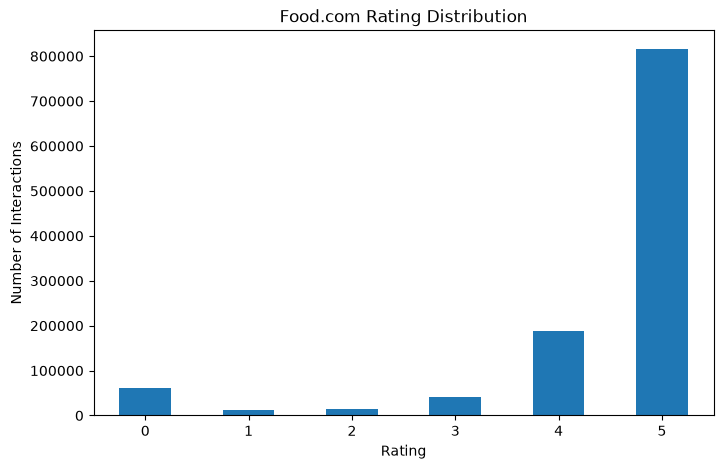

In [166]:
import matplotlib.pyplot as plt

rating_counts.plot(kind="bar", figsize=(8, 5))

plt.title("Food.com Rating Distribution")
plt.xlabel("Rating")
plt.ylabel("Number of Interactions")
plt.xticks(rotation=0)
plt.show()

In [167]:
print(interactions["rating"].describe())

count    1.132367e+06
mean     4.411016e+00
std      1.264752e+00
min      0.000000e+00
25%      4.000000e+00
50%      5.000000e+00
75%      5.000000e+00
max      5.000000e+00
Name: rating, dtype: float64


In [168]:
print("Mean rating:", interactions["rating"].mean())

print("Median rating:", interactions["rating"].median())

Mean rating: 4.411016039852804
Median rating: 5.0


In [169]:
print("Unique users:", interactions["user_id"].nunique())

print("Unique recipes:", interactions["recipe_id"].nunique())

print("Total interactions:", len(interactions))

Unique users: 226570
Unique recipes: 231637
Total interactions: 1132367


In [170]:
user_interactions = interactions.groupby("user_id").size().sort_values(ascending=False)

display(user_interactions.describe())

count    226570.000000
mean          4.997868
std          49.663111
min           1.000000
25%           1.000000
50%           1.000000
75%           2.000000
max        7671.000000
dtype: float64

In [171]:
display(user_interactions.head(20).to_frame("interaction_count"))

,interaction_count
user_id,
424680,7671
37449,5603
383346,4628
169430,4076
128473,3917
89831,3353
58104,3288
133174,3107
199848,3018


In [172]:
recipe_interactions = interactions.groupby("recipe_id").size().sort_values(ascending=False)

display(recipe_interactions.describe())

count    231637.000000
mean          4.888541
std          17.532481
min           1.000000
25%           1.000000
50%           2.000000
75%           4.000000
max        1613.000000
dtype: float64

In [173]:
display(recipe_interactions.head(20).to_frame("interaction_count"))

,interaction_count
recipe_id,
2886,1613
27208,1601
89204,1579
39087,1448
67256,1322
54257,1305
22782,1234
32204,1220
69173,997


In [174]:
recipe_rating_stats = (
    interactions.groupby("recipe_id")
    .agg(rating_mean=("rating", "mean"), rating_count=("rating", "count"))
    .sort_values("rating_count", ascending=False)
)

display(recipe_rating_stats.head(20))

,rating_mean,rating_count
recipe_id,,
2886,4.185989,1613
27208,4.288570,1601
89204,4.220393,1579
39087,4.541436,1448
67256,4.329047,1322
54257,4.213793,1305
22782,4.423015,1234
32204,4.525410,1220
69173,4.708124,997


In [175]:
recipe_rating_stats["rating_mean"].describe()

count    231637.000000
mean          4.346246
std           0.990806
min           0.000000
25%           4.000000
50%           4.714286
75%           5.000000
max           5.000000
Name: rating_mean, dtype: float64

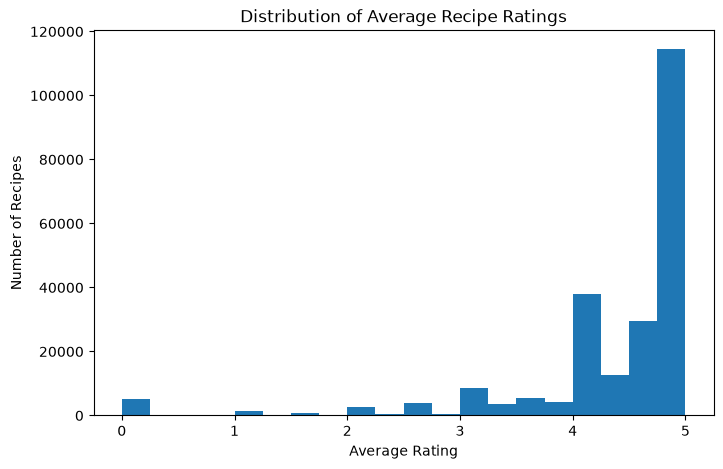

In [176]:
recipe_rating_stats["rating_mean"].plot(kind="hist", bins=20, figsize=(8, 5))

plt.title("Distribution of Average Recipe Ratings")
plt.xlabel("Average Rating")
plt.ylabel("Number of Recipes")
plt.show()

In [177]:
print(interactions["rating"].value_counts().sort_index())

rating
0     60847
1     12818
2     14123
3     40855
4    187360
5    816364
Name: count, dtype: int64


In [178]:
interactions["positive"] = (interactions["rating"] >= 4).astype(int)

print(interactions["positive"].value_counts())

print(interactions["positive"].value_counts(normalize=True) * 100)

positive
1    1003724
0     128643
Name: count, dtype: int64
positive
1    88.639461
0    11.360539
Name: proportion, dtype: float64


In [179]:
review_lengths = interactions["review"].fillna("").astype(str).str.len()

print(review_lengths.describe())

count    1.132367e+06
mean     2.783679e+02
std      1.974117e+02
min      0.000000e+00
25%      1.470000e+02
50%      2.370000e+02
75%      3.580000e+02
max      8.587000e+03
Name: review, dtype: float64


In [180]:
print("Empty reviews:", (review_lengths == 0).sum())

print("Non-empty reviews:", (review_lengths > 0).sum())

Empty reviews: 169
Non-empty reviews: 1132198


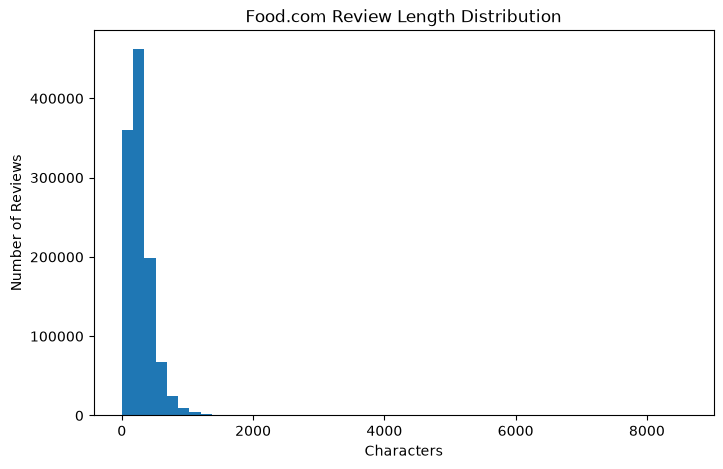

In [181]:
review_lengths.plot(kind="hist", bins=50, figsize=(8, 5))

plt.title("Food.com Review Length Distribution")
plt.xlabel("Characters")
plt.ylabel("Number of Reviews")
plt.show()

In [182]:
top_recipe_ids = interactions["recipe_id"].value_counts().head(20)

top_recipes = (
    recipes[["id", "name"]]
    .merge(top_recipe_ids.rename("interaction_count"), left_on="id", right_index=True, how="inner")
    .sort_values("interaction_count", ascending=False)
)

display(top_recipes)

,id,name,interaction_count
22168,2886,best banana bread,1613
213826,27208,to die for crock pot roast,1601
66687,89204,crock pot chicken with black beans cream cheese,1579
62431,39087,creamy cajun chicken pasta,1448
22388,67256,best ever banana cake with cream cheese frosting,1322
229262,54257,yes virginia there is a great meatloaf,1305
115303,22782,jo mama s world famous spaghetti,1234
574,32204,whatever floats your boat brownies,1220
118161,69173,kittencal s italian melt in your mouth meatballs,997
114444,68955,japanese mum s chicken,904


In [183]:
popular_rated_recipes = recipe_rating_stats[recipe_rating_stats["rating_count"] >= 20].sort_values(
    ["rating_mean", "rating_count"], ascending=[False, False]
)

display(popular_rated_recipes.head(30))

,rating_mean,rating_count
recipe_id,,
55309,5.0,52
24768,5.0,37
166669,5.0,36
121941,5.0,36
62754,5.0,32
199171,5.0,31
269136,5.0,31
94087,5.0,28
45107,5.0,28


In [184]:
popular_rated_recipes_named = (
    recipes[["id", "name"]]
    .merge(popular_rated_recipes.reset_index(), left_on="id", right_on="recipe_id", how="inner")
    .sort_values(["rating_mean", "rating_count"], ascending=[False, False])
)

display(popular_rated_recipes_named.head(30))

,id,name,recipe_id,rating_mean,rating_count
1273,55309,caprese salad tomatoes italian marinated tomatoes,55309,5.0,52
783,24768,berry cream cheese coffee cake,24768,5.0,37
4204,166669,kittencal s caesar tortellini salad,166669,5.0,36
4303,121941,kittencal s soft white baguette style bread,121941,5.0,36
4515,62754,linda s special potato salad,62754,5.0,32
1103,199171,broiled cinnamon toast,199171,5.0,31
2610,269136,earth bread,269136,5.0,31
2091,94087,cranberry nut swirls,94087,5.0,28
2400,495202,crunchy valley chicken rsc,495202,5.0,28
6926,45107,strawberry cheese ring,45107,5.0,28


In [185]:
n_users = interactions["user_id"].nunique()
n_recipes = interactions["recipe_id"].nunique()
n_interactions = len(interactions)

total_possible = n_users * n_recipes

sparsity = (1 - n_interactions / total_possible) * 100

print("Users:", n_users)
print("Recipes:", n_recipes)
print("Interactions:", n_interactions)
print(f"Interaction sparsity: {sparsity:.4f}%")

Users: 226570
Recipes: 231637
Interactions: 1132367
Interaction sparsity: 99.9978%


In [187]:
train_interactions = pd.read_csv(os.path.join(DATA_PATH, "interactions_train.csv"))

test_interactions = pd.read_csv(os.path.join(DATA_PATH, "interactions_test.csv"))

validation_interactions = pd.read_csv(os.path.join(DATA_PATH, "interactions_validation.csv"))

print("Train:", train_interactions.shape)
print("Validation:", validation_interactions.shape)
print("Test:", test_interactions.shape)

Train: (698901, 6)
Validation: (7023, 6)
Test: (12455, 6)


In [188]:
print("Train columns:")
print(train_interactions.columns.tolist())

print("\nValidation columns:")
print(validation_interactions.columns.tolist())

print("\nTest columns:")
print(test_interactions.columns.tolist())

Train columns:
['user_id', 'recipe_id', 'date', 'rating', 'u', 'i']

Validation columns:
['user_id', 'recipe_id', 'date', 'rating', 'u', 'i']

Test columns:
['user_id', 'recipe_id', 'date', 'rating', 'u', 'i']


In [189]:
display(train_interactions.head())
display(validation_interactions.head())
display(test_interactions.head())

,user_id,recipe_id,date,rating,u,i
0,2046,4684,2000-02-25,5.0,22095,44367
1,2046,517,2000-02-25,5.0,22095,87844
2,1773,7435,2000-03-13,5.0,24732,138181
3,1773,278,2000-03-13,4.0,24732,93054
4,2046,3431,2000-04-07,5.0,22095,101723


,user_id,recipe_id,date,rating,u,i
0,76535,33627,2005-02-15,4.0,5,177317
1,160497,75307,2005-10-24,4.0,23,170785
2,930021,100961,2008-11-30,4.0,31,165555
3,58439,154105,2007-03-24,4.0,44,177453
4,628951,14525,2008-02-16,5.0,45,142367


,user_id,recipe_id,date,rating,u,i
0,8937,44551,2005-12-23,4.0,2,173538
1,56680,126118,2006-10-07,4.0,16,177847
2,349752,219596,2008-04-12,0.0,26,89896
3,628951,82783,2007-11-13,2.0,45,172637
4,92816,435013,2013-07-31,3.0,52,177935


In [190]:
print("Train users:", train_interactions["user_id"].nunique())

print("Validation users:", validation_interactions["user_id"].nunique())

print("Test users:", test_interactions["user_id"].nunique())

print()

print("Train recipes:", train_interactions["recipe_id"].nunique())

print("Validation recipes:", validation_interactions["recipe_id"].nunique())

print("Test recipes:", test_interactions["recipe_id"].nunique())

Train users: 25076
Validation users: 7023
Test users: 12455

Train recipes: 160901
Validation recipes: 6621
Test recipes: 11695


In [191]:
print("=" * 65)
print("STAGE 5 — FOOD.COM INTERACTION EDA SUMMARY")
print("=" * 65)

print(f"Total interactions:       {len(interactions):,}")
print(f"Unique users:             {interactions['user_id'].nunique():,}")
print(f"Unique recipes:           {interactions['recipe_id'].nunique():,}")

print(f"\nMean rating:              {interactions['rating'].mean():.2f}")
print(f"Median rating:            {interactions['rating'].median():.2f}")

print(f"\nPositive interactions:     {interactions['positive'].sum():,}")

print(f"Positive rate:            {interactions['positive'].mean() * 100:.2f}%")

print(f"\nNon-empty reviews:        {(review_lengths > 0).sum():,}")

print(f"Interaction sparsity:     {sparsity:.4f}%")

print("\nSplit sizes:")
print("Train:", train_interactions.shape)
print("Validation:", validation_interactions.shape)
print("Test:", test_interactions.shape)

print("=" * 65)

STAGE 5 — FOOD.COM INTERACTION EDA SUMMARY
Total interactions:       1,132,367
Unique users:             226,570
Unique recipes:           231,637

Mean rating:              4.41
Median rating:            5.00

Positive interactions:     1,003,724
Positive rate:            88.64%

Non-empty reviews:        1,132,198
Interaction sparsity:     99.9978%

Split sizes:
Train: (698901, 6)
Validation: (7023, 6)
Test: (12455, 6)


In [192]:
# Check how many interaction recipe IDs exist in RAW_recipes

recipe_ids = set(recipes["id"])

interaction_recipe_ids = set(interactions["recipe_id"])

common_recipe_ids = recipe_ids.intersection(interaction_recipe_ids)

print("Recipes in RAW_recipes:", len(recipe_ids))
print("Recipes in interactions:", len(interaction_recipe_ids))
print("Common recipe IDs:", len(common_recipe_ids))

print(
    f"Interaction recipes covered by RAW_recipes: "
    f"{len(common_recipe_ids) / len(interaction_recipe_ids) * 100:.2f}%"
)

Recipes in RAW_recipes: 231637
Recipes in interactions: 231637
Common recipe IDs: 231637
Interaction recipes covered by RAW_recipes: 100.00%


In [193]:
all_users = set(interactions["user_id"])
train_users = set(train_interactions["user_id"])
val_users = set(validation_interactions["user_id"])
test_users = set(test_interactions["user_id"])

print("All interaction users:", len(all_users))
print("Train users:", len(train_users))
print("Validation users:", len(val_users))
print("Test users:", len(test_users))

print("\nTrain ∩ Validation users:", len(train_users.intersection(val_users)))

print("Train ∩ Test users:", len(train_users.intersection(test_users)))

print("Validation ∩ Test users:", len(val_users.intersection(test_users)))

All interaction users: 226570
Train users: 25076
Validation users: 7023
Test users: 12455

Train ∩ Validation users: 7023
Train ∩ Test users: 12455
Validation ∩ Test users: 5839


In [194]:
interaction_recipe_coverage = interactions[interactions["recipe_id"].isin(recipe_ids)]

print("Interactions with matching recipe:", len(interaction_recipe_coverage))

print(f"Coverage: {len(interaction_recipe_coverage) / len(interactions) * 100:.2f}%")

Interactions with matching recipe: 1132367
Coverage: 100.00%


In [195]:
recipes_final = recipes[
    ["id", "name", "ingredients", "tags", "nutrition", "n_steps", "n_ingredients"]
].copy()

recipes_final = recipes_final.rename(columns={"id": "recipe_id"})

print("Final recipe table shape:", recipes_final.shape)

display(recipes_final.head())

Final recipe table shape: (231637, 7)


,recipe_id,name,ingredients,tags,nutrition,n_steps,n_ingredients
0,137739,arriba baked winter squash mexican style,"['winter squash', 'mexican seasoning', 'mixed spice', 'honey', 'butter', 'olive oil', 'salt']","['60-minutes-or-less', 'time-to-make', 'course', 'main-ingredient', 'cuisine', 'preparation', 'o...","[51.5, 0.0, 13.0, 0.0, 2.0, 0.0, 4.0]",11,7
1,31490,a bit different breakfast pizza,"['prepared pizza crust', 'sausage patty', 'eggs', 'milk', 'salt and pepper', 'cheese']","['30-minutes-or-less', 'time-to-make', 'course', 'main-ingredient', 'cuisine', 'preparation', 'o...","[173.4, 18.0, 0.0, 17.0, 22.0, 35.0, 1.0]",9,6
2,112140,all in the kitchen chili,"['ground beef', 'yellow onions', 'diced tomatoes', 'tomato paste', 'tomato soup', 'rotel tomatoe...","['time-to-make', 'course', 'preparation', 'main-dish', 'chili', 'crock-pot-slow-cooker', 'dietar...","[269.8, 22.0, 32.0, 48.0, 39.0, 27.0, 5.0]",6,13
3,59389,alouette potatoes,"['spreadable cheese with garlic and herbs', 'new potatoes', 'shallots', 'parsley', 'tarragon', '...","['60-minutes-or-less', 'time-to-make', 'course', 'main-ingredient', 'preparation', 'occasion', '...","[368.1, 17.0, 10.0, 2.0, 14.0, 8.0, 20.0]",11,11
4,44061,amish tomato ketchup for canning,"['tomato juice', 'apple cider vinegar', 'sugar', 'salt', 'pepper', 'clove oil', 'cinnamon oil', ...","['weeknight', 'time-to-make', 'course', 'main-ingredient', 'cuisine', 'preparation', 'occasion',...","[352.9, 1.0, 337.0, 23.0, 3.0, 0.0, 28.0]",5,8


In [196]:
recipes_final["ingredients_list"] = recipes["ingredients_list"].values

recipes_final["tags_list"] = recipes["tags_list"].values

display(recipes_final[["recipe_id", "name", "ingredients_list", "tags_list"]].head())

,recipe_id,name,ingredients_list,tags_list
0,137739,arriba baked winter squash mexican style,"[winter squash, mexican seasoning, mixed spice, honey, butter, olive oil, salt]","[60-minutes-or-less, time-to-make, course, main-ingredient, cuisine, preparation, occasion, nort..."
1,31490,a bit different breakfast pizza,"[prepared pizza crust, sausage patty, eggs, milk, salt and pepper, cheese]","[30-minutes-or-less, time-to-make, course, main-ingredient, cuisine, preparation, occasion, nort..."
2,112140,all in the kitchen chili,"[ground beef, yellow onions, diced tomatoes, tomato paste, tomato soup, rotel tomatoes, kidney b...","[time-to-make, course, preparation, main-dish, chili, crock-pot-slow-cooker, dietary, equipment,..."
3,59389,alouette potatoes,"[spreadable cheese with garlic and herbs, new potatoes, shallots, parsley, tarragon, olive oil, ...","[60-minutes-or-less, time-to-make, course, main-ingredient, preparation, occasion, side-dishes, ..."
4,44061,amish tomato ketchup for canning,"[tomato juice, apple cider vinegar, sugar, salt, pepper, clove oil, cinnamon oil, dry mustard]","[weeknight, time-to-make, course, main-ingredient, cuisine, preparation, occasion, north-america..."


In [198]:
import pandas as pd

nutrition_columns = [
    "calories",
    "total_fat",
    "sugar",
    "sodium",
    "protein",
    "saturated_fat",
    "carbohydrates",
]

# Convert string representation of lists to actual Python lists if needed
if isinstance(recipes_final["nutrition"].iloc[0], str):
    parsed_nutrition = recipes_final["nutrition"].apply(ast.literal_eval)
else:
    parsed_nutrition = recipes_final["nutrition"]

# Create the DataFrame with 7 distinct columns
nutrition_df = pd.DataFrame(
    parsed_nutrition.tolist(), columns=nutrition_columns, index=recipes_final.index
)

# Concatenate back to recipes_final
recipes_final = pd.concat([recipes_final.drop(columns=["nutrition"]), nutrition_df], axis=1)

display(recipes_final.head())

,recipe_id,name,ingredients,tags,n_steps,n_ingredients,ingredients_list,tags_list,calories,total_fat,sugar,sodium,protein,saturated_fat,carbohydrates
0,137739,arriba baked winter squash mexican style,"['winter squash', 'mexican seasoning', 'mixed spice', 'honey', 'butter', 'olive oil', 'salt']","['60-minutes-or-less', 'time-to-make', 'course', 'main-ingredient', 'cuisine', 'preparation', 'o...",11,7,"[winter squash, mexican seasoning, mixed spice, honey, butter, olive oil, salt]","[60-minutes-or-less, time-to-make, course, main-ingredient, cuisine, preparation, occasion, nort...",51.5,0.0,13.0,0.0,2.0,0.0,4.0
1,31490,a bit different breakfast pizza,"['prepared pizza crust', 'sausage patty', 'eggs', 'milk', 'salt and pepper', 'cheese']","['30-minutes-or-less', 'time-to-make', 'course', 'main-ingredient', 'cuisine', 'preparation', 'o...",9,6,"[prepared pizza crust, sausage patty, eggs, milk, salt and pepper, cheese]","[30-minutes-or-less, time-to-make, course, main-ingredient, cuisine, preparation, occasion, nort...",173.4,18.0,0.0,17.0,22.0,35.0,1.0
2,112140,all in the kitchen chili,"['ground beef', 'yellow onions', 'diced tomatoes', 'tomato paste', 'tomato soup', 'rotel tomatoe...","['time-to-make', 'course', 'preparation', 'main-dish', 'chili', 'crock-pot-slow-cooker', 'dietar...",6,13,"[ground beef, yellow onions, diced tomatoes, tomato paste, tomato soup, rotel tomatoes, kidney b...","[time-to-make, course, preparation, main-dish, chili, crock-pot-slow-cooker, dietary, equipment,...",269.8,22.0,32.0,48.0,39.0,27.0,5.0
3,59389,alouette potatoes,"['spreadable cheese with garlic and herbs', 'new potatoes', 'shallots', 'parsley', 'tarragon', '...","['60-minutes-or-less', 'time-to-make', 'course', 'main-ingredient', 'preparation', 'occasion', '...",11,11,"[spreadable cheese with garlic and herbs, new potatoes, shallots, parsley, tarragon, olive oil, ...","[60-minutes-or-less, time-to-make, course, main-ingredient, preparation, occasion, side-dishes, ...",368.1,17.0,10.0,2.0,14.0,8.0,20.0
4,44061,amish tomato ketchup for canning,"['tomato juice', 'apple cider vinegar', 'sugar', 'salt', 'pepper', 'clove oil', 'cinnamon oil', ...","['weeknight', 'time-to-make', 'course', 'main-ingredient', 'cuisine', 'preparation', 'occasion',...",5,8,"[tomato juice, apple cider vinegar, sugar, salt, pepper, clove oil, cinnamon oil, dry mustard]","[weeknight, time-to-make, course, main-ingredient, cuisine, preparation, occasion, north-america...",352.9,1.0,337.0,23.0,3.0,0.0,28.0


In [199]:
print("Shape:", recipes_final.shape)

print("\nColumns:")
print(recipes_final.columns.tolist())

print("\nMissing values:")
display(recipes_final.isnull().sum())

Shape: (231637, 15)

Columns:
['recipe_id', 'name', 'ingredients', 'tags', 'n_steps', 'n_ingredients', 'ingredients_list', 'tags_list', 'calories', 'total_fat', 'sugar', 'sodium', 'protein', 'saturated_fat', 'carbohydrates']

Missing values:


recipe_id           0
name                1
ingredients         0
tags                0
n_steps             0
n_ingredients       0
ingredients_list    0
tags_list           0
calories            0
total_fat           0
sugar               0
sodium              0
protein             0
saturated_fat       0
carbohydrates       0
dtype: int64

In [200]:
interactions_final = interactions[["user_id", "recipe_id", "rating", "date"]].copy()

print("Final interaction table:", interactions_final.shape)

display(interactions_final.head())

Final interaction table: (1132367, 4)


,user_id,recipe_id,rating,date
0,38094,40893,4,2003-02-17
1,1293707,40893,5,2011-12-21
2,8937,44394,4,2002-12-01
3,126440,85009,5,2010-02-27
4,57222,85009,5,2011-10-01


In [201]:
interactions_final["positive"] = (interactions_final["rating"] >= 4).astype(int)

display(interactions_final.head())

,user_id,recipe_id,rating,date,positive
0,38094,40893,4,2003-02-17,1
1,1293707,40893,5,2011-12-21,1
2,8937,44394,4,2002-12-01,1
3,126440,85009,5,2010-02-27,1
4,57222,85009,5,2011-10-01,1


In [202]:
interactions_final = interactions_final[
    interactions_final["recipe_id"].isin(recipes_final["recipe_id"])
].copy()

print("Interactions after recipe matching:", interactions_final.shape)

Interactions after recipe matching: (1132367, 5)


In [203]:
ingredient_map_final = ingr_map[["raw_ingr", "processed", "replaced", "count", "id"]].copy()

print("Ingredient mapping table:", ingredient_map_final.shape)

display(ingredient_map_final.head())

Ingredient mapping table: (11659, 5)


,raw_ingr,processed,replaced,count,id
0,"medium heads bibb or red leaf lettuce, washed, dried* and torn into pieces","medium heads bibb or red leaf lettuce, washed, dried* and torn into piece",lettuce,4507,4308
1,mixed baby lettuces and spring greens,mixed baby lettuces and spring green,lettuce,4507,4308
2,romaine lettuce leaf,romaine lettuce leaf,lettuce,4507,4308
3,iceberg lettuce leaf,iceberg lettuce leaf,lettuce,4507,4308
4,red romaine lettuce,red romaine lettuce,lettuce,4507,4308


In [204]:
print("recipes_final memory:")
print(f"{recipes_final.memory_usage(deep=True).sum() / 1024**2:.2f} MB")

print("\ninteractions_final memory:")
print(f"{interactions_final.memory_usage(deep=True).sum() / 1024**2:.2f} MB")

print("\ningredient_map_final memory:")
print(f"{ingredient_map_final.memory_usage(deep=True).sum() / 1024**2:.2f} MB")

recipes_final memory:
231.50 MB

interactions_final memory:
98.27 MB

ingredient_map_final memory:
2.37 MB


In [205]:
OUTPUT_PATH = os.path.join(DATA_PATH, "processed_foodcom")

os.makedirs(OUTPUT_PATH, exist_ok=True)

recipes_final.to_pickle(os.path.join(OUTPUT_PATH, "recipes_final.pkl"))

interactions_final.to_pickle(os.path.join(OUTPUT_PATH, "interactions_final.pkl"))

ingredient_map_final.to_pickle(os.path.join(OUTPUT_PATH, "ingredient_map_final.pkl"))

print("Saved processed Food.com tables to:")
print(OUTPUT_PATH)

Saved processed Food.com tables to:
.\processed_foodcom


In [206]:
print("=" * 70)
print("FOOD.COM FINAL DATASET SUMMARY")
print("=" * 70)

print("\nRECIPE TABLE")
print("-------------------------")
print("Recipes:", len(recipes_final))
print("Columns:", len(recipes_final.columns))

print("\nINTERACTION TABLE")
print("-------------------------")
print("Interactions:", len(interactions_final))
print("Users:", interactions_final["user_id"].nunique())
print("Recipes:", interactions_final["recipe_id"].nunique())

print("\nINGREDIENT MAP")
print("-------------------------")
print("Raw ingredients:", ingredient_map_final["raw_ingr"].nunique())
print("Processed ingredients:", ingredient_map_final["processed"].nunique())
print("Ingredient IDs:", ingredient_map_final["id"].nunique())

print("\nFILES TO USE IN MVP")
print("-------------------------")
print("1. recipes_final.pkl")
print("2. interactions_final.pkl")
print("3. ingredient_map_final.pkl")

print("=" * 70)

FOOD.COM FINAL DATASET SUMMARY

RECIPE TABLE
-------------------------
Recipes: 231637
Columns: 15

INTERACTION TABLE
-------------------------
Interactions: 1132367
Users: 226570
Recipes: 231637

INGREDIENT MAP
-------------------------
Raw ingredients: 11659
Processed ingredients: 9035
Ingredient IDs: 8023

FILES TO USE IN MVP
-------------------------
1. recipes_final.pkl
2. interactions_final.pkl
3. ingredient_map_final.pkl
